# KDD Cup 1998 GenAI workshop: backup code for every step (prompt file v8)

This is the code an assistant would generate for `kddcup1998_workshop_modeling_v8.md`, one cell per step.
Run the cells in order (or Run All). Every step writes its printed output, tables and plots to `reports/`:

- `reports/stepNN_log.txt`: everything the step printed
- `reports/stepNN_<table>.csv`: every table the step reports
- `reports/plots/stepNN_<plot>.png`: every plot

Data: the first of the paths in `DATA_CANDIDATES` that exists. Python: Anaconda base (scikit-learn, xgboost, scipy, pandas, matplotlib).
Step 12 uses Dean's input shuffling framework (`input_shuffling_v2`) if it can be imported; otherwise a notebook-native version.

## Notebook initialization (global standards: timing, seeds, metadata, report files)

In [1]:
import os, sys, time, json, types, warnings
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

# ---------- configuration ----------
RANDOM_STATE = 42
MAILING_COST = 0.68
DATA_CANDIDATES = [
    Path("../data/cup98lrn_prepped_allrecords_w_TargetD.tsv"),                 # repository layout: data/ next to this folder
    Path("data/cup98lrn_prepped_allrecords_w_TargetD.tsv"),
    Path("cup98lrn_prepped_allrecords_w_TargetD.tsv"),                         # next to this notebook
    Path.home() / "cup98lrn_prepped_allrecords_w_TargetD.tsv",
]
DATA_FILE = next((p for p in DATA_CANDIDATES if p.exists()), None)
assert DATA_FILE is not None, f"data file not found; looked in {[str(p) for p in DATA_CANDIDATES]}"
# Optional: Dean Abbott's input_shuffling package (github.com/abbottanalytics/input_shuffling, licensed AGPL-3.0).
# Clone it next to this repository, or set the INPUT_SHUFFLING_SRC environment variable to its src/ folder.
# If it is not found, the step uses the short notebook-native version below (MIT, like the rest of this repository).
INPUT_SHUFFLING_SRC = next((p for p in [Path(os.environ.get("INPUT_SHUFFLING_SRC", "__none__")), Path("../../input_shuffling/src"),
                                        Path("../input_shuffling/src"), Path("input_shuffling/src")] if p.exists()), Path("input_shuffling/src"))
REPORT_DIR = Path("reports"); PLOT_DIR = REPORT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print("Data file:", DATA_FILE)
print("Reports  :", REPORT_DIR)

# ---------- timing, seed and runtime logs (restart-safe: created only if missing) ----------
if "notebook_timing_log" not in globals(): notebook_timing_log = []
if "random_seed_log" not in globals(): random_seed_log = []

class _Tee:
    """Send printed output to the notebook and to the step's log file."""
    def __init__(self, a, b): self.a, self.b = a, b
    def write(self, s): self.a.write(s); self.b.write(s); return len(s)
    def flush(self): self.a.flush(); self.b.flush()
    def __getattr__(self, k): return getattr(self.a, k)

if "_ORIG_STDOUT" not in globals(): _ORIG_STDOUT = sys.stdout

def step_start(step_number, step_name):
    """Banner, start time, and start teeing output to reports/stepNN_log.txt."""
    global step_start_time, step_start_timestamp, CURRENT_STEP, CURRENT_STEP_NAME, _STEP_LOG
    CURRENT_STEP, CURRENT_STEP_NAME = step_number, step_name
    sys.stdout = _ORIG_STDOUT
    _STEP_LOG = open(REPORT_DIR / f"step{step_number:02d}_log.txt", "w")
    sys.stdout = _Tee(_ORIG_STDOUT, _STEP_LOG)
    step_start_time = time.time(); step_start_timestamp = datetime.now()
    print("=" * 78); print(f"RUNNING STEP {step_number} — {step_name}")
    print(f"Start: {step_start_timestamp:%Y-%m-%d %H:%M:%S}"); print("=" * 78)

def step_end(objects_created="", notes=""):
    """Completion banner, elapsed time, timing row, close the step log."""
    global step_end_time, step_end_timestamp, step_elapsed_seconds, step_elapsed_minutes, notebook_timing_df
    step_end_time = time.time(); step_end_timestamp = datetime.now()
    step_elapsed_seconds = step_end_time - step_start_time; step_elapsed_minutes = step_elapsed_seconds / 60
    notebook_timing_log[:] = [r for r in notebook_timing_log if r["step_number"] != CURRENT_STEP]   # a rerun replaces its own row
    notebook_timing_log.append(dict(step_number=CURRENT_STEP, step_name=CURRENT_STEP_NAME,
        start_timestamp=step_start_timestamp, end_timestamp=step_end_timestamp,
        elapsed_seconds=round(step_elapsed_seconds, 2), elapsed_minutes=round(step_elapsed_minutes, 3), major_runtime_notes=notes))
    notebook_timing_df = pd.DataFrame(notebook_timing_log)
    print("=" * 78); print(f"STEP {CURRENT_STEP} COMPLETE — {step_elapsed_seconds:.1f} s ({step_elapsed_minutes:.2f} min)")
    if objects_created: print("Objects created:", objects_created)
    if notes: print("Notes:", notes)
    print("=" * 78)
    sys.stdout = _ORIG_STDOUT; _STEP_LOG.close()

class timed:
    """Within-step runtime reporting; flags anything over 60 s."""
    def __init__(self, label): self.label = label
    def __enter__(self): self.t = time.time(); return self
    def __exit__(self, *a):
        self.seconds = time.time() - self.t
        print(f"   [{self.label}] {self.seconds:.2f} s" + ("  <-- LONG (>60 s)" if self.seconds > 60 else ""))

def log_seed(step_number, action_name, seed_value, function_or_parameter, notes=""):
    random_seed_log.append(dict(step_number=step_number, action_name=action_name, seed_value=seed_value,
                                function_or_parameter=function_or_parameter, notes=notes))

def show_seeds(step_number):
    d = pd.DataFrame(random_seed_log)
    if len(d):
        d = d[d.step_number == step_number]
        print("\nRandom seeds used in this step:\n", d.to_string(index=False))
        save_table(d, "random_seeds")

def save_table(df, name, index=False):
    """Write a report table to reports/stepNN_<name>.csv."""
    df.to_csv(REPORT_DIR / f"step{CURRENT_STEP:02d}_{name}.csv", index=index)

def save_fig(fig, name):
    """Save a plot to reports/plots/stepNN_<name>.png and show it."""
    fig.savefig(PLOT_DIR / f"step{CURRENT_STEP:02d}_{name}.png", dpi=90, bbox_inches="tight")
    plt.show(); plt.close(fig)

def show(df, title=None, n=None):
    if title: print(f"\n{title}")
    print((df if n is None else df.head(n)).to_string())

TEST_PEAK_NOTE = ("NOTE: 'TEST peak (optimistic)' is the best mailing depth found by looking at the TEST data itself. "
                  "It is an upper bound, not what the model would earn. In production, set the threshold or depth on "
                  "TRAINING data (e.g. where cumulative net revenue peaks on out-of-fold training predictions) and apply it unchanged.")

Data file: ../data/cup98lrn_prepped_allrecords_w_TargetD.tsv
Reports  : reports


## STEP 1 — LOAD DATA

In [2]:
step_start(1, "LOAD DATA")
with timed("read_csv"):
    df_raw = pd.read_csv(DATA_FILE, sep="\t", low_memory=False)
if "RECORD_ID" not in df_raw.columns:
    df_raw.insert(0, "RECORD_ID", np.arange(1, len(df_raw) + 1)); print("RECORD_ID created (1..n).")
df_raw = df_raw.set_index("RECORD_ID", drop=False)

cat_cols = df_raw.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in df_raw.select_dtypes(include=[np.number]).columns if c != "RECORD_ID"]
print("1) Rows, columns:", df_raw.shape)
print("\n2) Variable names:\n", list(df_raw.columns))
dtypes_df = df_raw.dtypes.astype(str).rename("dtype").to_frame(); show(dtypes_df, "3) Data types:"); save_table(dtypes_df, "dtypes", index=True)
tb = df_raw["TARGET_B"].value_counts().rename("count").to_frame(); tb["pct"] = tb["count"] / len(df_raw)
show(tb, "4) TARGET_B distribution:"); save_table(tb, "target_b_distribution", index=True)
td = pd.concat([df_raw["TARGET_D"].describe().rename("all_records"),
                df_raw.loc[df_raw.TARGET_B == 1, "TARGET_D"].describe().rename("responders")], axis=1)
show(td.round(2), "5) TARGET_D summary:"); save_table(td, "target_d_summary", index=True)
print("\n6) Categorical variables:", cat_cols or "none (all inputs are numeric: dummies, counts, log10 amounts)")
missing_counts = df_raw.isna().sum(); missing_counts = missing_counts[missing_counts > 0]
print("\n7) Variables with missing values:", "none" if missing_counts.empty else "");
if len(missing_counts): print(missing_counts.to_string())
numeric_audit_df = df_raw[num_cols].describe(percentiles=[.25, .5, .75]).T.rename(
    columns={"50%": "median", "25%": "Q1", "75%": "Q3", "std": "std_dev"})[["min", "max", "mean", "median", "std_dev", "Q1", "Q3"]]
numeric_audit_df["n_unique"] = df_raw[num_cols].nunique()
show(numeric_audit_df.round(3), "8) Numeric summary:"); save_table(numeric_audit_df, "numeric_summary", index=True)
step_end("df_raw, numeric_audit_df")

RUNNING STEP 1 — LOAD DATA
Start: 2026-11-13 22:40:49
   [read_csv] 0.21 s
RECORD_ID created (1..n).
1) Rows, columns: (95412, 35)

2) Variable names:
 ['RECORD_ID', 'CARDPM12', 'LASTDATE', 'RFA_2F', 'AGE_modelimpute', 'CA_STATE', 'TN_STATE', 'R2_DOMAIN', 'C3_DOMAIN', 'HIT_gt4_HIT', 'L3D_RFA_2', 'L4E_RFA_2', 'L1F_RFA_2', 'L2G_RFA_2', 'L1G_RFA_2', 'L3E_RFA_2', 'L2E_RFA_2', 'L4D_RFA_2', 'L4F_RFA_2', 'E_RFA_2A', 'F_RFA_2A', 'G_RFA_2A', '12_CLUSTER2', '54_CLUSTER2', '43_CLUSTER2', '13_CLUSTER2', '51_CLUSTER2', 'NUMPRM12_log10', 'NGIFTALL_log10', 'MINRAMNT_log10', 'LASTGIFT_log10', 'TIMELAG_log10', 'AVGGIFT_log10', 'TARGET_B', 'TARGET_D']

3) Data types:
                   dtype
RECORD_ID          int64
CARDPM12           int64
LASTDATE           int64
RFA_2F             int64
AGE_modelimpute    int64
CA_STATE           int64
TN_STATE           int64
R2_DOMAIN          int64
C3_DOMAIN          int64
HIT_gt4_HIT        int64
L3D_RFA_2          int64
L4E_RFA_2          int64
L1F_RFA_2        

## STEP 2 — DATA PREPARATION

In [3]:
step_start(2, "DATA PREPARATION")
modeling_prepared_df = df_raw.copy()          # master dataframe for the rest of the notebook (Step 14 uses this name)
TARGETS = ["TARGET_B", "TARGET_D"]
TARGET_B_ORIG, TARGET_D_ORIG = modeling_prepared_df["TARGET_B"].copy(), modeling_prepared_df["TARGET_D"].copy()
modeling_prepared_df["TARGET_B_label"] = modeling_prepared_df["TARGET_B"].map({1: "responder", 0: "non_responder"}).astype("category")

predictor_cols = [c for c in modeling_prepared_df.columns if c not in TARGETS + ["RECORD_ID", "TARGET_B_label"]]
num_pred = [c for c in predictor_cols if pd.api.types.is_numeric_dtype(modeling_prepared_df[c])]
cat_pred = [c for c in predictor_cols if c not in num_pred]
binary_cols = [c for c in num_pred if set(modeling_prepared_df[c].dropna().unique()) <= {0, 1}]
continuous_cols = [c for c in num_pred if c not in binary_cols]

# 2) numeric missing -> median;  3) categorical missing -> explicit "MISSING" level (keeps missingness as information)
missing_before = modeling_prepared_df[predictor_cols].isna().sum()
imputation_medians = modeling_prepared_df[num_pred].median()
modeling_prepared_df[num_pred] = modeling_prepared_df[num_pred].fillna(imputation_medians)
for c in cat_pred: modeling_prepared_df[c] = modeling_prepared_df[c].fillna("MISSING")
print("Missing values: none in this file" if missing_before.sum() == 0 else "Missing values imputed (see table)")
missing_report_df = pd.DataFrame({"missing": missing_before, "pct_missing": 100 * missing_before / len(modeling_prepared_df)})
save_table(missing_report_df, "missing_report", index=True)

# 4) near-zero variance, skew (non-binary only), leakage screen
top_share = modeling_prepared_df[num_pred].apply(lambda s: s.value_counts(normalize=True).iloc[0])
near_zero_variance = top_share[top_share > 0.99].index.tolist()
print("\nNear-zero-variance variables (>99% one value):", near_zero_variance or "none")
skewness_df = modeling_prepared_df[continuous_cols].skew().rename("skewness").to_frame()
skewness_df["abs_skew"] = skewness_df.skewness.abs(); skewness_df = skewness_df.sort_values("abs_skew", ascending=False)
show(skewness_df.round(3), f"6) Skewness of non-binary numeric variables ({len(binary_cols)} binary 0/1 variables excluded):")
save_table(skewness_df, "skewness", index=True)
highly_skewed = skewness_df.index[skewness_df.abs_skew > 1].tolist()
print("Highly skewed (|skew| > 1):", highly_skewed or "none")

# 5) monetary variables actually present
monetary_vars = [c for c in num_pred if any(k in c.upper() for k in ["GIFT", "RAMNT", "AMNT"])]
monetary_df = pd.DataFrame({"variable": monetary_vars, "already_transformed": [c.endswith("_log10") for c in monetary_vars],
                            "skewness": [modeling_prepared_df[c].skew() for c in monetary_vars]})
show(monetary_df.round(3), "5) Monetary variables present (raw LASTGIFT / AVGGIFT / RAMNT are not in this file; only log10 versions):")
save_table(monetary_df, "monetary_variables")

leak_corr = modeling_prepared_df[num_pred].corrwith(modeling_prepared_df["TARGET_B"]).abs().sort_values(ascending=False)
suspicious_leakage = leak_corr[leak_corr > 0.3].index.tolist()
show(leak_corr.head(10).round(3).rename("abs_corr_with_TARGET_B").to_frame(), "Leakage screen: top |correlation| with TARGET_B")
save_table(leak_corr.rename("abs_corr_with_TARGET_B").to_frame(), "leakage_screen", index=True)
print("Suspicious leakage variables (|r| > 0.3):", suspicious_leakage or "none (TARGET_D is excluded from all inputs)")

# N-1 / overlapping encodings for linear and logistic models (global rule 17a)
rfa_combo_dummies = [c for c in num_pred if c.startswith("L") and c.endswith("_RFA_2")]
model_features_base = [c for c in predictor_cols if c not in near_zero_variance]
linear_features_base = [c for c in model_features_base if c not in rfa_combo_dummies]
A = np.column_stack([np.ones(len(modeling_prepared_df)), modeling_prepared_df[model_features_base].to_numpy(float)])
A_lin = np.column_stack([np.ones(len(modeling_prepared_df)), modeling_prepared_df[linear_features_base].to_numpy(float)])
encoding_report_df = pd.DataFrame([
    dict(feature_set="all inputs (tree models, NB, NN)", n_features=len(model_features_base),
         rank_with_intercept=np.linalg.matrix_rank(A), columns_with_intercept=A.shape[1]),
    dict(feature_set="linear/logistic (L*_RFA_2 dropped)", n_features=len(linear_features_base),
         rank_with_intercept=np.linalg.matrix_rank(A_lin), columns_with_intercept=A_lin.shape[1])])
show(encoding_report_df, "N-1 / overlapping-encoding check:")
print("E_RFA_2A + F_RFA_2A + G_RFA_2A + L3D_RFA_2 + L4D_RFA_2 = 1 for every row:",
      bool((modeling_prepared_df[["E_RFA_2A", "F_RFA_2A", "G_RFA_2A", "L3D_RFA_2", "L4D_RFA_2"]].sum(axis=1) == 1).all()))
print("Linear and logistic models drop the combined RFA_2 dummies:", rfa_combo_dummies)
save_table(encoding_report_df, "encoding_check")
del A, A_lin
step_end("modeling_prepared_df, skewness_df, model_features_base, linear_features_base")

RUNNING STEP 2 — DATA PREPARATION
Start: 2026-11-13 22:40:49
Missing values: none in this file

Near-zero-variance variables (>99% one value): none

6) Skewness of non-binary numeric variables (22 binary 0/1 variables excluded):
                 skewness  abs_skew
TIMELAG_log10       1.894     1.894
NUMPRM12_log10      0.814     0.814
RFA_2F              0.786     0.786
LASTDATE            0.720     0.720
LASTGIFT_log10     -0.480     0.480
MINRAMNT_log10      0.393     0.393
AVGGIFT_log10       0.382     0.382
CARDPM12            0.312     0.312
NGIFTALL_log10     -0.074     0.074
AGE_modelimpute    -0.044     0.044
Highly skewed (|skew| > 1): ['TIMELAG_log10']

5) Monetary variables present (raw LASTGIFT / AVGGIFT / RAMNT are not in this file; only log10 versions):
         variable  already_transformed  skewness
0  NGIFTALL_log10                 True    -0.074
1  MINRAMNT_log10                 True     0.393
2  LASTGIFT_log10                 True    -0.480
3   AVGGIFT_log10         

## STEP 3 — TRAIN / HOLD-OUT SPLIT

In [4]:
step_start(3, "TRAIN / HOLD-OUT SPLIT")
from sklearn.model_selection import train_test_split
TEST_SIZE = 0.30
if "split_flag" not in modeling_prepared_df:          # never regenerate the split
    train_ids, test_ids = train_test_split(modeling_prepared_df.index, test_size=TEST_SIZE,
                                           stratify=modeling_prepared_df["TARGET_B"], random_state=RANDOM_STATE)
    log_seed(3, "train/test split", RANDOM_STATE, "train_test_split(random_state=RANDOM_STATE)", "stratified on TARGET_B, 70/30")
    modeling_prepared_df["split_flag"] = "TRAIN"; modeling_prepared_df.loc[test_ids, "split_flag"] = "TEST"
train_df = modeling_prepared_df[modeling_prepared_df.split_flag == "TRAIN"]
test_df = modeling_prepared_df[modeling_prepared_df.split_flag == "TEST"]
split_report_df = pd.DataFrame([dict(dataset="TRAIN", n=len(train_df), response_rate=train_df.TARGET_B.mean(), pct=len(train_df) / len(modeling_prepared_df)),
                                dict(dataset="TEST", n=len(test_df), response_rate=test_df.TARGET_B.mean(), pct=len(test_df) / len(modeling_prepared_df))])
show(split_report_df.round(4), "Split:"); save_table(split_report_df, "split")
show_seeds(3)
step_end("split_flag in modeling_prepared_df, train_df, test_df")

RUNNING STEP 3 — TRAIN / HOLD-OUT SPLIT
Start: 2026-11-13 22:40:50

Split:
  dataset      n  response_rate  pct
0   TRAIN  66788         0.0508  0.7
1    TEST  28624         0.0508  0.3

Random seeds used in this step:
  step_number      action_name  seed_value                       function_or_parameter                         notes
           3 train/test split          42 train_test_split(random_state=RANDOM_STATE) stratified on TARGET_B, 70/30
STEP 3 COMPLETE — 1.7 s (0.03 min)
Objects created: split_flag in modeling_prepared_df, train_df, test_df


## STEP 4 — BUILD TARGET_B CLASSIFICATION MODELS

RUNNING STEP 4 — BUILD TARGET_B CLASSIFICATION MODELS
Start: 2026-11-13 22:40:51
Classification threshold = training response rate = 0.0508 (not 0.5)
   [fit lr] 0.11 s
   [score lr] 0.03 s
   [fit nb] 0.15 s
   [score nb] 0.15 s
   [fit gbm] 1.46 s
   [score gbm] 0.22 s
   [fit nn] 3.07 s
   [score nn] 0.12 s
   [fit rf] 4.69 s
   [score rf] 1.29 s

TARGET_B metrics, ranked by test lift at decile 3, then test ROC AUC:
  model  train_baseline_rate  train_roc_auc  train_f1  train_accuracy  train_precision  train_recall  train_lift_decile3  test_baseline_rate  test_roc_auc  test_f1  test_accuracy  test_precision  test_recall  test_lift_decile3
2   gbm               0.0508         0.6757    0.1402          0.5946           0.0785        0.6510              1.7600              0.0508        0.6255   0.1273         0.5847          0.0712       0.5967             1.5828
4    rf               0.0508         0.7469    0.1662          0.6341           0.0939        0.7183              2.1042   

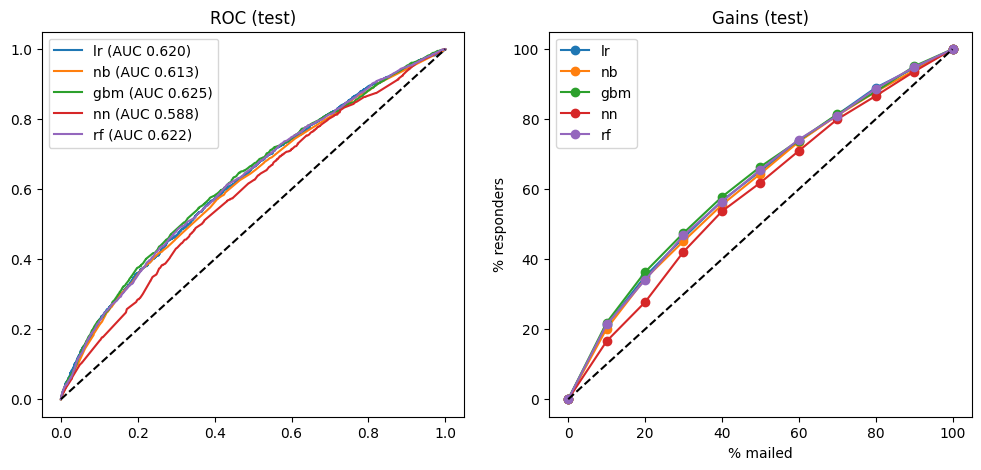

   [top-10 predictors per model] 2.72 s

Top 10 predictors per model:
model             gbm              lr             nb              nn               rf
rank                                                                                 
1              RFA_2F        G_RFA_2A      L4D_RFA_2        F_RFA_2A    AVGGIFT_log10
2      LASTGIFT_log10        F_RFA_2A      L3D_RFA_2        E_RFA_2A  AGE_modelimpute
3            CA_STATE  NGIFTALL_log10      L4E_RFA_2        G_RFA_2A         LASTDATE
4       AVGGIFT_log10        LASTDATE       TN_STATE          RFA_2F   NGIFTALL_log10
5            LASTDATE          RFA_2F      L4F_RFA_2  LASTGIFT_log10   LASTGIFT_log10
6            CARDPM12        CA_STATE      L2G_RFA_2       L3E_RFA_2    TIMELAG_log10
7           L1G_RFA_2  MINRAMNT_log10    51_CLUSTER2       L4D_RFA_2   NUMPRM12_log10
8         12_CLUSTER2  NUMPRM12_log10       CARDPM12   AVGGIFT_log10           RFA_2F
9         13_CLUSTER2     51_CLUSTER2       LASTDATE        LASTDATE  

In [5]:
step_start(4, "BUILD TARGET_B CLASSIFICATION MODELS")
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score, precision_score, recall_score, roc_curve,
                             mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier

def decile_table(y_true, score, value=None, n=10):
    """Decile table sorted by score (highest first). value = $ column for donation lift."""
    d = pd.DataFrame({"y": np.asarray(y_true, float), "s": np.asarray(score, float)})
    if value is not None: d["v"] = np.asarray(value, float)
    d = d.sort_values("s", ascending=False, kind="stable").reset_index(drop=True)
    d["decile"] = (np.arange(len(d)) * n // len(d)) + 1
    g = d.groupby("decile").agg(n=("y", "size"), responders=("y", "sum"), mean_score=("s", "mean"))
    base = d.y.mean()
    g["response_rate"] = g.responders / g.n; g["cum_response_rate"] = g.responders.cumsum() / g.n.cumsum()
    g["lift"] = g.response_rate / base; g["cum_lift"] = g.cum_response_rate / base
    g["cum_pct_responders"] = g.responders.cumsum() / g.responders.sum()
    if value is not None:
        vs = d.groupby("decile").v.agg(["sum", "mean"]); g["donation_sum"], g["donation_mean"] = vs["sum"], vs["mean"]
        g["cum_donation_lift"] = (g.donation_sum.cumsum() / g.n.cumsum()) / d.v.mean()
    return g

def clf_metrics(y, p, threshold):
    yhat = (p >= threshold).astype(int)
    return dict(baseline_rate=y.mean(), roc_auc=roc_auc_score(y, p), f1=f1_score(y, yhat), accuracy=accuracy_score(y, yhat),
                precision=precision_score(y, yhat, zero_division=0), recall=recall_score(y, yhat),
                lift_decile3=decile_table(y, p).loc[3, "cum_lift"])

if "model_metadata_df" not in globals():
    model_metadata_df = pd.DataFrame(columns=["model_name", "model_family", "approach_type", "target_variable", "transformed_target_flag",
        "feature_list_name", "feature_count", "prediction_column_name", "hyperparameters", "training_metrics", "testing_metrics",
        "cumulative_net_revenue", "optimal_depth", "train_runtime_seconds", "scoring_runtime_seconds", "total_runtime_seconds", "notes"])
def add_metadata(**row):
    global model_metadata_df
    if row["model_name"] in set(model_metadata_df.model_name): print(f"   metadata for {row['model_name']} exists — not overwritten"); return
    model_metadata_df = pd.concat([model_metadata_df, pd.DataFrame([row])], ignore_index=True)

if "predictions_target_b_train" not in globals():
    predictions_target_b_train, predictions_target_b_test = pd.DataFrame(), pd.DataFrame()
def store_preds(store_name, ids, actual, model_name, pred, dataset, family, transformed=False):
    globals()[store_name] = pd.concat([globals()[store_name], pd.DataFrame({"RECORD_ID": ids, "actual": actual, "model_name": model_name,
        "prediction": pred, "dataset": dataset, "model_family": family, "transformed": transformed})], ignore_index=True)

target_b_feature_sets = {"lr": linear_features_base, "nb": model_features_base, "gbm": model_features_base,
                         "nn": model_features_base, "rf": model_features_base}
for key, fam in [("lr", "logistic"), ("nb", "naive_bayes"), ("gbm", "gbm"), ("nn", "nn"), ("rf", "rf")]:
    nm = f"target_b_{fam}_features"
    if nm not in globals():
        globals()[nm] = dict(variables=list(target_b_feature_sets[key]), transformed_versions="monetary inputs already log10 in the file",
                             excluded=["TARGET_B", "TARGET_D", "RECORD_ID", "TARGET_B_label", "split_flag"] + (rfa_combo_dummies if key == "lr" else []),
                             leakage_removals=["TARGET_D"], encoding="N-1, L*_RFA_2 dropped" if key == "lr" else "all numeric inputs")
y_tr, y_te = train_df["TARGET_B"].values, test_df["TARGET_B"].values
THRESHOLD = y_tr.mean()
print(f"Classification threshold = training response rate = {THRESHOLD:.4f} (not 0.5)")

calib = lambda est: CalibratedClassifierCV(est, method="isotonic", cv=3)
target_b_model_specs = {
    "lr":  ("logistic", make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE)), False),
    "nb":  ("naive_bayes", GaussianNB(), True),
    "gbm": ("gbm", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                 random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss"), True),
    "nn":  ("nn", make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-3, early_stopping=True,
                                                                max_iter=300, random_state=RANDOM_STATE)), True),
    "rf":  ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE), True),
}
for k, (fam, est, _) in target_b_model_specs.items():
    if "random_state" in str(est.get_params()): log_seed(4, f"{k} model", RANDOM_STATE, "random_state=RANDOM_STATE", fam)
log_seed(4, "isotonic calibration folds", "n/a", "CalibratedClassifierCV(cv=3): unshuffled stratified folds", "deterministic")

target_b_results = {}
for key, (fam, est, use_cal) in target_b_model_specs.items():
    model_name, pred_col, feats = f"model_{key}_target_b", f"pred_{key}_target_b", target_b_feature_sets[key]
    if model_name in globals(): print(f"{model_name} exists — skipping refit"); continue
    model = calib(est) if use_cal else est
    with timed(f"fit {key}") as tf: model.fit(train_df[feats], y_tr)
    with timed(f"score {key}") as ts: p_tr, p_te = model.predict_proba(train_df[feats])[:, 1], model.predict_proba(test_df[feats])[:, 1]
    globals()[model_name] = model
    modeling_prepared_df.loc[train_df.index, pred_col] = p_tr; modeling_prepared_df.loc[test_df.index, pred_col] = p_te
    store_preds("predictions_target_b_train", train_df.index, y_tr, model_name, p_tr, "TRAIN", fam)
    store_preds("predictions_target_b_test", test_df.index, y_te, model_name, p_te, "TEST", fam)
    m_tr, m_te = clf_metrics(y_tr, p_tr, THRESHOLD), clf_metrics(y_te, p_te, THRESHOLD)
    target_b_results[key] = (m_tr, m_te)
    add_metadata(model_name=model_name, model_family=fam, approach_type="target_b_classification", target_variable="TARGET_B",
        transformed_target_flag=False, feature_list_name=f"target_b_{fam}_features", feature_count=len(feats), prediction_column_name=pred_col,
        hyperparameters=json.dumps({k: str(v) for k, v in est.get_params().items() if "__" not in k or key in ("lr", "nn")})[:2000],
        training_metrics=m_tr, testing_metrics=m_te, cumulative_net_revenue=np.nan, optimal_depth=np.nan,
        train_runtime_seconds=tf.seconds, scoring_runtime_seconds=ts.seconds, total_runtime_seconds=tf.seconds + ts.seconds,
        notes="isotonic calibration (cv=3)" if use_cal else "logistic probabilities used directly")

target_b_metrics_df = pd.DataFrame([{"model": k, **{f"train_{a}": b for a, b in v[0].items()}, **{f"test_{a}": b for a, b in v[1].items()}}
                                    for k, v in target_b_results.items()]).sort_values(["test_lift_decile3", "test_roc_auc"], ascending=False)
show(target_b_metrics_df.round(4), "TARGET_B metrics, ranked by test lift at decile 3, then test ROC AUC:")
save_table(target_b_metrics_df, "target_b_metrics")
target_b_decile_tables = {k: decile_table(y_te, modeling_prepared_df.loc[test_df.index, f"pred_{k}_target_b"]) for k in target_b_results}
for k, dt in target_b_decile_tables.items(): save_table(dt, f"decile_table_{k}", index=True)
show(target_b_decile_tables[target_b_metrics_df.model.iloc[0]].round(3), f"Test decile table, best model ({target_b_metrics_df.model.iloc[0]}):")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for k in target_b_results:
    p = modeling_prepared_df.loc[test_df.index, f"pred_{k}_target_b"]
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(y_te, p):.3f})")
    dt = target_b_decile_tables[k]; ax[1].plot([0] + list(dt.index * 10), [0] + list(dt.cum_pct_responders * 100), marker="o", label=k)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC (test)"); ax[0].legend()
ax[1].plot([0, 100], [0, 100], "k--"); ax[1].set_title("Gains (test)"); ax[1].set_xlabel("% mailed"); ax[1].set_ylabel("% responders"); ax[1].legend()
save_fig(fig, "roc_gains")

# top-10 predictors per model (used by Step 14)
def _inner(est):
    return [c.estimator for c in est.calibrated_classifiers_] if isinstance(est, CalibratedClassifierCV) else [est]
target_b_top_features, importance_rows = {}, []
imp_sample = test_df.sample(5000, random_state=RANDOM_STATE)
log_seed(4, "permutation importance sample + repeats", RANDOM_STATE, "DataFrame.sample / permutation_importance(random_state)", "NB and NN")
with timed("top-10 predictors per model"):
    for key in target_b_results:
        m, feats = globals()[f"model_{key}_target_b"], target_b_feature_sets[key]
        inner = _inner(m)
        if key == "lr":
            imp = np.abs(m.named_steps["logisticregression"].coef_[0]); how = "|standardized coefficient|"
        elif hasattr(inner[0], "feature_importances_"):
            imp = np.mean([e.feature_importances_ for e in inner], axis=0); how = "built-in importance (mean over calibration folds)"
        else:
            r = permutation_importance(m, imp_sample[feats], imp_sample.TARGET_B, scoring="roc_auc", n_repeats=3,
                                       random_state=RANDOM_STATE, n_jobs=1)
            imp = r.importances_mean; how = "permutation importance (ROC AUC, 5,000 test rows)"
        s = pd.Series(imp, index=feats).sort_values(ascending=False)
        target_b_top_features[key] = s.index[:10].tolist()
        importance_rows += [dict(model=key, rank=i + 1, variable=v, importance=s[v], method=how) for i, v in enumerate(s.index[:10])]
target_b_top_features_df = pd.DataFrame(importance_rows)
show(target_b_top_features_df.pivot(index="rank", columns="model", values="variable"), "Top 10 predictors per model:")
save_table(target_b_top_features_df, "top10_predictors")
target_b_parameter_report = model_metadata_df.loc[model_metadata_df.approach_type == "target_b_classification", ["model_name", "hyperparameters", "notes"]]
save_table(target_b_parameter_report, "parameter_report")
model_runtime_summary_df = model_metadata_df[["model_name", "train_runtime_seconds", "scoring_runtime_seconds", "total_runtime_seconds"]]
show(model_runtime_summary_df.round(2), "Runtime per model:"); save_table(model_runtime_summary_df, "runtime")
show_seeds(4)
step_end("model_*_target_b, pred_*_target_b, predictions_target_b_*, model_metadata_df, target_b_metrics_df, target_b_top_features")

## STEP 5 — BUILD TARGET_D REGRESSION MODELS (responders only)

RUNNING STEP 5 — BUILD TARGET_D REGRESSION MODELS
Start: 2026-11-13 22:41:08
Responder rows: train 3,390  test 1,453
   [fit linreg] 0.02 s
   [score linreg] 0.04 s
   [fit gbm] 0.37 s
   [score gbm] 0.01 s
   [fit nn] 0.38 s
   [score nn] 0.00 s
   [fit rf] 0.59 s
   [score rf] 0.09 s
Linear regression: largest |coefficient| = 4.73 (no collinearity blow-up)

TARGET_D metrics (responders), ranked by test donation lift at decile 3, then RMSE:
    model  train_rmse  train_mae  train_r2  train_donation_lift_decile3  test_rmse  test_mae  test_r2  test_donation_lift_decile3
3      rf       7.540      3.520     0.623                        1.670      8.862     4.174    0.521                       1.659
0  linreg       8.894      4.585     0.476                        1.606      9.090     4.634    0.497                       1.650
1     gbm       6.327      3.603     0.735                        1.633      8.707     4.140    0.538                       1.650
2      nn       8.466      4.304  

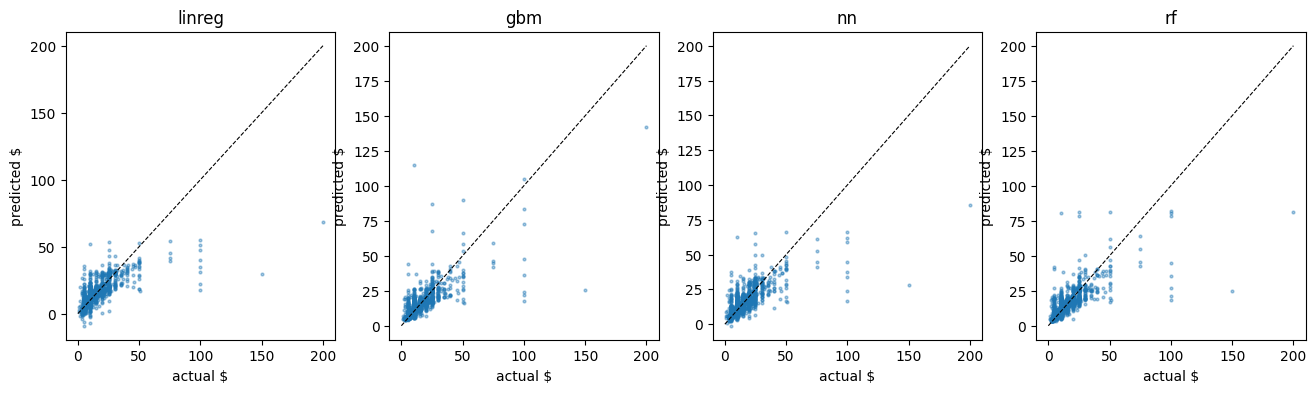


Random seeds used in this step:
  step_number           action_name seed_value     function_or_parameter                notes
           5          XGBRegressor         42 random_state=RANDOM_STATE TARGET_D, responders
           5          MLPRegressor         42 random_state=RANDOM_STATE TARGET_D, responders
           5 RandomForestRegressor         42 random_state=RANDOM_STATE TARGET_D, responders
STEP 5 COMPLETE — 2.0 s (0.03 min)
Objects created: model_*_target_d, pred_*_target_d, predictions_target_d_*, target_d_metrics_df


In [6]:
step_start(5, "BUILD TARGET_D REGRESSION MODELS")
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

def reg_metrics(y, pred):
    return dict(rmse=float(np.sqrt(mean_squared_error(y, pred))), mae=float(mean_absolute_error(y, pred)), r2=float(r2_score(y, pred)),
                donation_lift_decile3=float(decile_table(y, pred, value=y).loc[3, "cum_donation_lift"]))

if "predictions_target_d_train" not in globals():
    predictions_target_d_train, predictions_target_d_test = pd.DataFrame(), pd.DataFrame()
tr_r, te_r = train_df[train_df.TARGET_B == 1], test_df[test_df.TARGET_B == 1]
yd_tr, yd_te = tr_r.TARGET_D.values, te_r.TARGET_D.values
print(f"Responder rows: train {len(tr_r):,}  test {len(te_r):,}")

def make_regressors():
    return {"linreg": ("linear", make_pipeline(StandardScaler(), LinearRegression())),
            "gbm": ("gbm", XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                        random_state=RANDOM_STATE, n_jobs=-1)),
            "nn": ("nn", make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(16,), alpha=1e-2, early_stopping=True,
                                                                      max_iter=1000, random_state=RANDOM_STATE))),
            "rf": ("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=10, n_jobs=-1, random_state=RANDOM_STATE))}
for nm in ["XGBRegressor", "MLPRegressor", "RandomForestRegressor"]:
    log_seed(5, nm, RANDOM_STATE, "random_state=RANDOM_STATE", "TARGET_D, responders")

def fit_reg_family(suffix, feature_sets, ytr, inverse=None, transformed=False, feat_list_prefix="target_d"):
    """Fit the four regressors; feature_sets maps model key -> feature list. Predictions are on the dollar scale."""
    results = {}
    for key, (fam, est) in make_regressors().items():
        model_name, pred_col, feats = f"model_{key}{suffix}_target_d", f"pred_{key}{suffix}_target_d", feature_sets[key]
        if model_name in globals(): print(f"{model_name} exists — skip"); continue
        with timed(f"fit {key}{suffix}") as tf: est.fit(tr_r[feats], ytr)
        with timed(f"score {key}{suffix}") as ts: p_tr, p_te = est.predict(tr_r[feats]), est.predict(te_r[feats])
        if inverse is not None: p_tr, p_te = inverse(p_tr), inverse(p_te)
        globals()[model_name] = est
        modeling_prepared_df.loc[tr_r.index, pred_col] = p_tr; modeling_prepared_df.loc[te_r.index, pred_col] = p_te
        store_preds("predictions_target_d_train", tr_r.index, yd_tr, model_name, p_tr, "TRAIN", fam, transformed)
        store_preds("predictions_target_d_test", te_r.index, yd_te, model_name, p_te, "TEST", fam, transformed)
        m_tr, m_te = reg_metrics(yd_tr, p_tr), reg_metrics(yd_te, p_te); results[key] = (m_tr, m_te)
        add_metadata(model_name=model_name, model_family=fam,
            approach_type="transformed_target_d_regression" if transformed else "target_d_regression", target_variable="TARGET_D",
            transformed_target_flag=transformed, feature_list_name=f"{feat_list_prefix}_{fam}_features", feature_count=len(feats),
            prediction_column_name=pred_col, hyperparameters=json.dumps({k: str(v) for k, v in est.get_params().items()})[:2000],
            training_metrics=m_tr, testing_metrics=m_te, cumulative_net_revenue=np.nan, optimal_depth=np.nan,
            train_runtime_seconds=tf.seconds, scoring_runtime_seconds=ts.seconds, total_runtime_seconds=tf.seconds + ts.seconds,
            notes=("log1p target, expm1 back to dollars; " if transformed else "") + "trained on responders only")
    return results

target_d_feature_sets = {"linreg": linear_features_base, "gbm": model_features_base, "nn": model_features_base, "rf": model_features_base}
for key, fam in [("linreg", "linear"), ("gbm", "gbm"), ("nn", "nn"), ("rf", "rf")]:
    if f"target_d_{fam}_features" not in globals():
        globals()[f"target_d_{fam}_features"] = dict(variables=list(target_d_feature_sets[key]), excluded=["TARGET_B", "TARGET_D"],
            leakage_removals=["TARGET_B"], encoding="N-1, L*_RFA_2 dropped" if key == "linreg" else "all numeric inputs")
target_d_results = fit_reg_family("", target_d_feature_sets, yd_tr)
lin = model_linreg_target_d.named_steps["linearregression"]
print(f"Linear regression: largest |coefficient| = {np.abs(lin.coef_).max():,.2f} (no collinearity blow-up)")
target_d_metrics_df = pd.DataFrame([{"model": k, **{f"train_{a}": b for a, b in v[0].items()}, **{f"test_{a}": b for a, b in v[1].items()}}
                                    for k, v in target_d_results.items()]).sort_values(["test_donation_lift_decile3", "test_rmse"], ascending=[False, True])
show(target_d_metrics_df.round(3), "TARGET_D metrics (responders), ranked by test donation lift at decile 3, then RMSE:")
save_table(target_d_metrics_df, "target_d_metrics")
for k in target_d_results:
    save_table(decile_table(yd_te, modeling_prepared_df.loc[te_r.index, f"pred_{k}_target_d"], value=yd_te), f"donation_deciles_{k}", index=True)
best_d = target_d_metrics_df.model.iloc[0]
show(decile_table(yd_te, modeling_prepared_df.loc[te_r.index, f"pred_{best_d}_target_d"], value=yd_te)[["n", "donation_mean", "cum_donation_lift"]].round(2),
     f"Donation decile table (test responders, {best_d}):")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, k in zip(axes, target_d_results):
    ax.scatter(yd_te, modeling_prepared_df.loc[te_r.index, f"pred_{k}_target_d"], s=4, alpha=.4)
    ax.plot([0, yd_te.max()], [0, yd_te.max()], "k--", lw=.8); ax.set_title(k); ax.set_xlabel("actual $"); ax.set_ylabel("predicted $")
save_fig(fig, "pred_vs_actual")
target_d_parameter_report = model_metadata_df.loc[model_metadata_df.approach_type == "target_d_regression", ["model_name", "hyperparameters", "notes"]]
save_table(target_d_parameter_report, "parameter_report")
show_seeds(5)
step_end("model_*_target_d, pred_*_target_d, predictions_target_d_*, target_d_metrics_df")

## STEP 6 — BUILD TRANSFORMED TARGET_D MODELS

In [7]:
step_start(6, "BUILD TRANSFORMED TARGET_D MODELS")
modeling_prepared_df["TARGET_D_log1p"] = np.log1p(modeling_prepared_df["TARGET_D"])
cont_d = [c for c in model_features_base if c in continuous_cols]
sk_before = modeling_prepared_df[cont_d].skew()
to_transform = [c for c in cont_d if abs(sk_before[c]) > 1 and not c.endswith("_log10") and modeling_prepared_df[c].min() >= 0]
transform_report_df = pd.DataFrame({"variable": cont_d, "skew_before": sk_before.values})
transform_report_df["transformation"] = ["log1p" if c in to_transform else ("already log10 in file" if c.endswith("_log10") else "none (|skew| <= 1)")
                                         for c in cont_d]
transform_report_df["skew_after"] = [np.log1p(modeling_prepared_df[c]).skew() if c in to_transform else np.nan for c in cont_d]
show(transform_report_df.round(3), f"Continuous predictors ({len(binary_cols)} binary dummies are never transformed):")
save_table(transform_report_df, "transform_report")
for c in to_transform: modeling_prepared_df[f"{c}_log1p"] = np.log1p(modeling_prepared_df[c])
swap = lambda feats: [f"{c}_log1p" if c in to_transform else c for c in feats]
target_d_log_feature_sets = {k: swap(v) for k, v in target_d_feature_sets.items()}
for key, fam in [("linreg", "linear"), ("gbm", "gbm"), ("nn", "nn"), ("rf", "rf")]:
    if f"target_d_log_{fam}_features" not in globals():
        globals()[f"target_d_log_{fam}_features"] = dict(variables=target_d_log_feature_sets[key], transformed_versions=to_transform,
            excluded=["TARGET_B", "TARGET_D"], leakage_removals=["TARGET_B"], target="log1p(TARGET_D)")
tr_r, te_r = modeling_prepared_df.loc[tr_r.index], modeling_prepared_df.loc[te_r.index]
target_d_log_results = fit_reg_family("_log", target_d_log_feature_sets, tr_r.TARGET_D_log1p.values, np.expm1, True, "target_d_log")
transformed_vs_raw_df = pd.DataFrame([{"model": k, "raw_test_rmse": target_d_results[k][1]["rmse"], "log_test_rmse": target_d_log_results[k][1]["rmse"],
    "raw_test_mae": target_d_results[k][1]["mae"], "log_test_mae": target_d_log_results[k][1]["mae"],
    "raw_test_r2": target_d_results[k][1]["r2"], "log_test_r2": target_d_log_results[k][1]["r2"],
    "raw_lift3": target_d_results[k][1]["donation_lift_decile3"], "log_lift3": target_d_log_results[k][1]["donation_lift_decile3"]}
    for k in target_d_log_results])
show(transformed_vs_raw_df.round(3), "Transformed vs raw target (test responders, dollar scale after expm1):")
save_table(transformed_vs_raw_df, "transformed_vs_raw")
print("Note: expm1 of a log-scale prediction estimates the median gift, not the mean, so log models tend to under-predict dollars.")
step_end("TARGET_D_log1p, model_*_log_target_d, pred_*_log_target_d, transformed_vs_raw_df")

RUNNING STEP 6 — BUILD TRANSFORMED TARGET_D MODELS
Start: 2026-11-13 22:41:10

Continuous predictors (22 binary dummies are never transformed):
          variable  skew_before         transformation  skew_after
0         CARDPM12        0.312     none (|skew| <= 1)         NaN
1         LASTDATE        0.720     none (|skew| <= 1)         NaN
2           RFA_2F        0.786     none (|skew| <= 1)         NaN
3  AGE_modelimpute       -0.044     none (|skew| <= 1)         NaN
4   NUMPRM12_log10        0.814  already log10 in file         NaN
5   NGIFTALL_log10       -0.074  already log10 in file         NaN
6   MINRAMNT_log10        0.393  already log10 in file         NaN
7   LASTGIFT_log10       -0.480  already log10 in file         NaN
8    TIMELAG_log10        1.894  already log10 in file         NaN
9    AVGGIFT_log10        0.382  already log10 in file         NaN
   [fit linreg_log] 0.01 s
   [score linreg_log] 0.03 s
   [fit gbm_log] 0.55 s
   [score gbm_log] 0.01 s
   [fit nn_lo

## STEP 7 — CUMULATIVE NET REVENUE FOR ALL MODELS (TEST, no refits)

RUNNING STEP 7 — CUMULATIVE NET REVENUE EVALUATION
Start: 2026-11-13 22:41:12
Scored all 28,624 test rows with every model (13 models).
   [cumulative net revenue, all models] 0.06 s
Mail everyone in TEST (28,624 records): $2,933

Cumulative net revenue, ranked by TEST peak (optimistic):
                        model                    approach_type  TEST_peak_CNR_optimistic  optimal_depth_pct  mailed_at_optimum  roi_at_optimum  response_rate_at_optimum  donation_capture
5       model_linreg_target_d              target_d_regression                   4013.20              0.731              20935           0.282                     0.044             0.815
11      model_nn_log_target_d  transformed_target_d_regression                   3953.64              0.721              20627           0.282                     0.043             0.803
9   model_linreg_log_target_d  transformed_target_d_regression                   3941.84              0.751              21487           0.270        

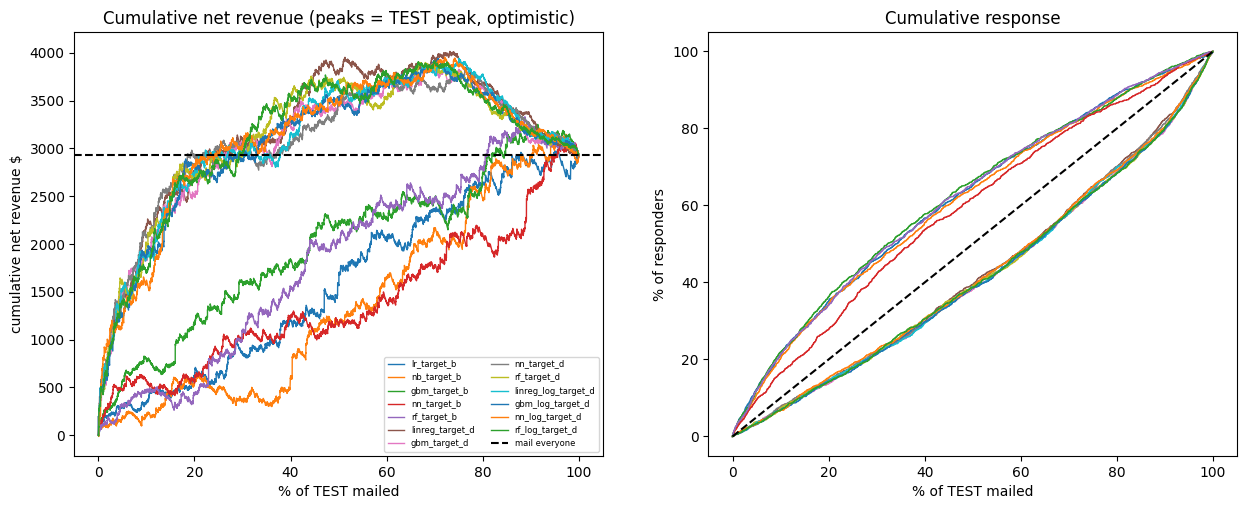

STEP 7 COMPLETE — 1.5 s (0.03 min)
Objects created: cnr_summary_df, cnr_tables, cnr_curves_df; model_metadata_df updated


In [8]:
step_start(7, "CUMULATIVE NET REVENUE EVALUATION")
test_full = modeling_prepared_df[modeling_prepared_df.split_flag == "TEST"].copy()
gift_test = test_full["TARGET_D"].to_numpy(float)
# TARGET_D models were trained on responders only: score EVERY test row (no refit)
for key in ["linreg", "gbm", "nn", "rf"]:
    for suffix, fsets, inv in [("", target_d_feature_sets, None), ("_log", target_d_log_feature_sets, np.expm1)]:
        col, m = f"pred_{key}{suffix}_target_d", globals()[f"model_{key}{suffix}_target_d"]
        need = test_full[col].isna()
        if need.any():
            p = m.predict(test_full.loc[need, fsets[key]]); p = inv(p) if inv is not None else p
            test_full.loc[need, col] = p; modeling_prepared_df.loc[test_full.index[need], col] = p
pred_cols = [c for c in test_full.columns if c.startswith("pred_") and (c.endswith("_target_b") or c.endswith("_target_d"))]
assert all(test_full[c].notna().all() for c in pred_cols), "null predictions remain"
print(f"Scored all {len(test_full):,} test rows with every model ({len(pred_cols)} models).")

def cnr_table(score, gift, mail_cost=MAILING_COST):
    order = np.argsort(-np.asarray(score, float), kind="stable"); g = gift[order]
    t = pd.DataFrame({"rank": np.arange(1, len(g) + 1), "gift": g})
    t["cum_donations"] = t.gift.cumsum(); t["cum_mail_cost"] = t["rank"] * mail_cost
    t["cum_net_revenue"] = t.cum_donations - t.cum_mail_cost
    t["cum_responders"] = (t.gift > 0).cumsum(); t["depth_pct"] = t["rank"] / len(t)
    return t

PEAK = "TEST_peak_CNR_optimistic"
def cnr_summary_row(name, approach, score, gift=None):
    gift = gift_test if gift is None else gift
    t = cnr_table(score, gift); i = int(t.cum_net_revenue.idxmax()); r = t.loc[i]
    return dict(model=name, approach_type=approach, **{PEAK: r.cum_net_revenue}, optimal_depth_pct=r.depth_pct,
                mailed_at_optimum=int(r["rank"]), roi_at_optimum=r.cum_net_revenue / r.cum_mail_cost,
                response_rate_at_optimum=r.cum_responders / r["rank"], donation_capture=r.cum_donations / gift.sum()), t

cnr_rows, cnr_tables = [], {}
with timed("cumulative net revenue, all models"):
    for col in pred_cols:
        mname = col.replace("pred_", "model_")
        appr = model_metadata_df.set_index("model_name").loc[mname, "approach_type"]
        row, t = cnr_summary_row(mname, appr, test_full[col].to_numpy()); cnr_rows.append(row); cnr_tables[mname] = t
cnr_summary_df = pd.DataFrame(cnr_rows).sort_values(PEAK, ascending=False)
mail_all = gift_test.sum() - MAILING_COST * len(gift_test)
print(f"Mail everyone in TEST ({len(gift_test):,} records): ${mail_all:,.0f}")
show(cnr_summary_df.round(3), "Cumulative net revenue, ranked by TEST peak (optimistic):")
print("\n" + TEST_PEAK_NOTE)
save_table(cnr_summary_df, "cnr_summary")
bad = cnr_summary_df[cnr_summary_df.response_rate_at_optimum >= 0.999]
assert bad.empty, f"invalid evaluation (response rate 1.0 at optimum): {bad.model.tolist()}"
for _, r in cnr_summary_df.iterrows():
    i = model_metadata_df.model_name == r.model
    model_metadata_df.loc[i, "cumulative_net_revenue"] = r[PEAK]; model_metadata_df.loc[i, "optimal_depth"] = r.optimal_depth_pct
# compact cumulative table (every 1% of the file) for each model
pct_grid = np.unique(np.clip((np.arange(1, 101) / 100 * len(gift_test)).astype(int) - 1, 0, None))
cnr_curves_df = pd.DataFrame({"depth_pct": cnr_tables[cnr_summary_df.model.iloc[0]].depth_pct.values[pct_grid]})
for m, t in cnr_tables.items(): cnr_curves_df[m] = t.cum_net_revenue.values[pct_grid]
save_table(cnr_curves_df, "cnr_curves_by_percent")
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for m, t in cnr_tables.items():
    ax[0].plot(t.depth_pct * 100, t.cum_net_revenue, lw=1, label=m.replace("model_", ""))
    ax[1].plot(t.depth_pct * 100, t.cum_responders / t.cum_responders.iloc[-1] * 100, lw=1)
ax[0].axhline(mail_all, ls="--", c="k", label="mail everyone"); ax[0].set_xlabel("% of TEST mailed"); ax[0].set_ylabel("cumulative net revenue $")
ax[0].set_title("Cumulative net revenue (peaks = TEST peak, optimistic)"); ax[0].legend(fontsize=6, ncol=2)
ax[1].plot([0, 100], [0, 100], "k--"); ax[1].set_title("Cumulative response"); ax[1].set_xlabel("% of TEST mailed"); ax[1].set_ylabel("% of responders")
save_fig(fig, "cnr_curves")
step_end("cnr_summary_df, cnr_tables, cnr_curves_df; model_metadata_df updated")

## STEP 8 — EXPECTED VALUE SCORES: P(TARGET_B) * predicted TARGET_D

RUNNING STEP 8 — BUILD EXPECTED VALUE SCORES
Start: 2026-11-13 22:41:14
   [expected value combinations] 0.31 s

Top 15 expected value combinations, by TEST peak (optimistic):
                        model  TEST_peak_CNR_optimistic  optimal_depth_pct  roi_at_optimum  donation_capture  ev_rule_cnr  ev_rule_mailed_pct
16      model_ev_gbm_x_linreg                   4750.60              0.358           0.681             0.523      4207.28               0.612
20  model_ev_gbm_x_linreg_log                   4745.36              0.376           0.648             0.539      4733.20               0.510
12   model_ev_nb_x_linreg_log                   4716.20              0.544           0.445             0.684      4526.32               0.572
22      model_ev_gbm_x_nn_log                   4710.72              0.479           0.505             0.627      4613.60               0.506
23      model_ev_gbm_x_rf_log                   4682.32              0.379           0.635             0.539      

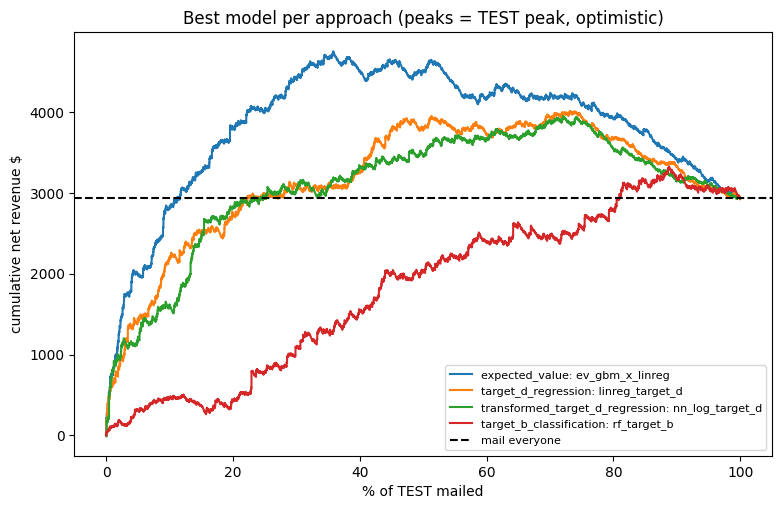

STEP 8 COMPLETE — 0.6 s (0.01 min)
Objects created: pred_ev_* columns, ev_summary_df, all_approaches_df


In [9]:
step_start(8, "BUILD EXPECTED VALUE SCORES")
b_cols = [c for c in pred_cols if c.endswith("_target_b")]
d_cols = [c for c in pred_cols if c.endswith("_target_d")]
ev_rows = []
with timed("expected value combinations"):
    for bc in b_cols:
        for dc in d_cols:
            ev = test_full[bc].to_numpy() * np.clip(test_full[dc].to_numpy(), 0, None)
            name = f"ev_{bc[5:-9]}_x_{dc[5:-9]}"; col = f"pred_{name}"
            if col not in modeling_prepared_df: modeling_prepared_df.loc[test_full.index, col] = ev
            test_full[col] = ev
            row, t = cnr_summary_row(f"model_{name}", "expected_value", ev); cnr_tables[f"model_{name}"] = t
            mail = ev > MAILING_COST
            row.update(ev_rule_cnr=float((gift_test[mail] - MAILING_COST).sum()), ev_rule_mailed_pct=float(mail.mean()), b_model=bc, d_model=dc)
            ev_rows.append(row)
            add_metadata(model_name=f"model_{name}", model_family="expected_value", approach_type="expected_value",
                target_variable="TARGET_B x TARGET_D", transformed_target_flag="_log" in dc, feature_list_name="(component models)",
                feature_count=np.nan, prediction_column_name=col, hyperparameters=json.dumps({"b": bc, "d": dc}), training_metrics={},
                testing_metrics={}, cumulative_net_revenue=row[PEAK], optimal_depth=row["optimal_depth_pct"], train_runtime_seconds=0.0,
                scoring_runtime_seconds=0.0, total_runtime_seconds=0.0, notes=f"EV > ${MAILING_COST} rule: ${row['ev_rule_cnr']:,.0f}")
ev_summary_df = pd.DataFrame(ev_rows).sort_values(PEAK, ascending=False)
all_approaches_df = pd.concat([cnr_summary_df, ev_summary_df], ignore_index=True).sort_values(PEAK, ascending=False).reset_index(drop=True)
show(ev_summary_df.head(15)[["model", PEAK, "optimal_depth_pct", "roi_at_optimum", "donation_capture", "ev_rule_cnr", "ev_rule_mailed_pct"]].round(3),
     "Top 15 expected value combinations, by TEST peak (optimistic):")
save_table(ev_summary_df, "ev_summary")
comparison_by_approach_df = all_approaches_df.groupby("approach_type").head(1)[["approach_type", "model", PEAK, "optimal_depth_pct", "roi_at_optimum", "donation_capture"]]
show(comparison_by_approach_df.round(3), "Best model per approach type (TEST peak, optimistic):")
save_table(comparison_by_approach_df, "best_per_approach"); save_table(all_approaches_df, "all_approaches_ranked")
print(f"\nMail everyone: ${mail_all:,.0f}")
print("\n" + TEST_PEAK_NOTE)
fig, ax = plt.subplots(figsize=(9, 5.5))
for _, r in comparison_by_approach_df.iterrows():
    t = cnr_tables[r.model]; ax.plot(t.depth_pct * 100, t.cum_net_revenue, label=f"{r.approach_type}: {r.model.replace('model_', '')}")
ax.axhline(mail_all, ls="--", c="k", label="mail everyone"); ax.legend(fontsize=8); ax.set_xlabel("% of TEST mailed"); ax.set_ylabel("cumulative net revenue $")
ax.set_title("Best model per approach (peaks = TEST peak, optimistic)")
save_fig(fig, "best_per_approach")
step_end("pred_ev_* columns, ev_summary_df, all_approaches_df")

## STEP 9 — FINAL MODEL COMPARISON (reporting only)

In [10]:
step_start(9, "FINAL MODEL COMPARISON")
CANON = ["target_b_classification", "target_d_regression", "transformed_target_d_regression", "expected_value"]
model_metadata_df["approach_type"] = model_metadata_df["approach_type"].replace(
    {"classification": "target_b_classification", "regression": "target_d_regression", "ev": "expected_value"})
assert set(model_metadata_df.approach_type) <= set(CANON)
assert model_metadata_df.prediction_column_name.is_unique, "duplicate prediction columns"

def safe_get(d, k):
    try:
        if isinstance(d, str): d = json.loads(d)
        return float(d.get(k, np.nan)) if isinstance(d, dict) else np.nan
    except Exception: return np.nan
stat = pd.DataFrame({"model_name": model_metadata_df.model_name, "approach_type": model_metadata_df.approach_type})
for k in ["roc_auc", "f1", "accuracy", "precision", "recall", "lift_decile3", "rmse", "mae", "r2", "donation_lift_decile3"]:
    stat[k] = model_metadata_df.testing_metrics.apply(lambda d: safe_get(d, k)).values
biz = all_approaches_df.rename(columns={"model": "model_name"})[["model_name", PEAK, "roi_at_optimum", "optimal_depth_pct", "mailed_at_optimum", "donation_capture"]]
final_comparison_df = stat.merge(biz, on="model_name", how="left", validate="one_to_one").sort_values(PEAK, ascending=False).reset_index(drop=True)
save_table(final_comparison_df, "final_comparison")
summary_tables = {}
for a in CANON:
    sub = final_comparison_df[final_comparison_df.approach_type == a]
    if sub.empty: print(f"WARNING: no rows for {a}"); continue
    summary_tables[a] = sub; keep = [c for c in sub.columns if sub[c].notna().any()]
    show(sub[keep].round(3), f"--- {a} ({len(sub)} models) ---", n=10); save_table(sub[keep], f"summary_{a}")
statistical_rankings_df = final_comparison_df.sort_values("roc_auc", ascending=False)
business_rankings_df = final_comparison_df.sort_values(PEAK, ascending=False)
save_table(business_rankings_df, "business_rankings")

def best(df, col, asc=False):
    df = df.dropna(subset=[col])
    if df.empty: print(f"WARNING: nothing to rank by {col}"); return None
    return df.sort_values(col, ascending=asc).iloc[0]
recs = {"best statistical TARGET_B (ROC AUC)": best(final_comparison_df[final_comparison_df.approach_type == "target_b_classification"], "roc_auc"),
        "best statistical TARGET_D (RMSE)": best(final_comparison_df[final_comparison_df.approach_type.str.contains("target_d")], "rmse", True),
        "best business model (TEST peak, optimistic)": best(final_comparison_df, PEAK)}
recommendation_summary_df = pd.DataFrame([{"recommendation": k, "model": v.model_name, "approach_type": v.approach_type, "roc_auc": v.roc_auc,
    "rmse": v.rmse, PEAK: v[PEAK], "optimal_depth_pct": v.optimal_depth_pct} for k, v in recs.items() if v is not None])
show(recommendation_summary_df.round(3), "Recommendations:"); save_table(recommendation_summary_df, "recommendations")
b_auc, bb = recs["best statistical TARGET_B (ROC AUC)"], recs["best business model (TEST peak, optimistic)"]
discussion_summary_df = pd.DataFrame({"topic": ["Statistical vs business metrics", "Ranking differences", "Why EV models win",
    "Operational implications", "Optimal mailing depth", "Risk of statistical-only selection", "TEST peak is optimistic"], "finding": [
    f"Highest-AUC response model {b_auc.model_name} (AUC {b_auc.roc_auc:.3f}) peaks at ${b_auc[PEAK]:,.0f}; the best business model {bb.model_name} peaks at ${bb[PEAK]:,.0f}.",
    "AUC and lift reward ranking responders; RMSE rewards gift accuracy among responders only; CNR rewards ranking dollars net of mail cost across everyone.",
    "EV combines who responds with how much they give, so it ranks likely large donors first.",
    f"The best EV model mails about {bb.optimal_depth_pct:.0%} of the file instead of everyone (mail-all ${mail_all:,.0f}).",
    "Depth sets cost and volume. The CNR curve is flat near its peak, so a slightly shallower mailing loses little.",
    "Choosing by AUC alone picks a response model whose CNR is well below the best EV model's.",
    "Every peak here is chosen on TEST. In production, set the depth on training data and apply it unchanged."]})
show(discussion_summary_df, "Discussion:"); save_table(discussion_summary_df, "discussion")
print("\n" + TEST_PEAK_NOTE)
step_end("final_comparison_df, summary_tables, recommendation_summary_df, discussion_summary_df")

RUNNING STEP 9 — FINAL MODEL COMPARISON
Start: 2026-11-13 22:41:14

--- target_b_classification (5 models) ---
            model_name            approach_type  roc_auc     f1  accuracy  precision  recall  lift_decile3  TEST_peak_CNR_optimistic  roi_at_optimum  optimal_depth_pct  mailed_at_optimum  donation_capture
48   model_rf_target_b  target_b_classification    0.622  0.128     0.617      0.072   0.553         1.560                   3330.20           0.193              0.888              25410             0.920
49  model_gbm_target_b  target_b_classification    0.625  0.127     0.585      0.071   0.597         1.583                   3249.64           0.183              0.915              26177             0.940
50   model_nb_target_b  target_b_classification    0.613  0.124     0.608      0.070   0.548         1.505                   3145.48           0.166              0.973              27864             0.986
51   model_nn_target_b  target_b_classification    0.588  0.115     0

## STEP 10 — HYPERPARAMETER TUNING
Workshop note: settings are scored on TEST because the workshop is instructional. In production, tune with cross-validation
inside TRAIN and keep TEST for one final evaluation; choosing settings by TEST CNR is leaderboard-style overfitting.

RUNNING STEP 10 — HYPERPARAMETER TUNING
Start: 2026-11-13 22:41:14
Best business strategy so far: model_ev_gbm_x_linreg TEST peak $4,751
Best expected value model: model_ev_gbm_x_linreg  (response component: gbm, gift component: linreg)
Tuning 8 combinations (limit 20). Each component is tuned with the other held at its untuned version.
   [tune gbm {'max_depth': 2, 'n_estimators': 150}] 0.88 s
   [tune gbm {'max_depth': 2, 'n_estimators': 400}] 1.92 s
   [tune gbm {'max_depth': 3, 'n_estimators': 150}] 0.82 s
   [tune gbm {'max_depth': 3, 'n_estimators': 400}] 1.62 s
   [tune gbm {'max_depth': 4, 'n_estimators': 150}] 0.95 s
   [tune gbm {'max_depth': 4, 'n_estimators': 400}] 2.03 s
   [tune linreg {'positive': False}] 0.00 s
   [tune linreg {'positive': True}] 0.01 s

Tuning results (EV TEST peak, optimistic):
         component                                 params  test_auc  ev_TEST_peak_cnr   depth  mailed     roi  seconds
0     gbm_target_b  {"max_depth": 2, "n_estimators": 150}

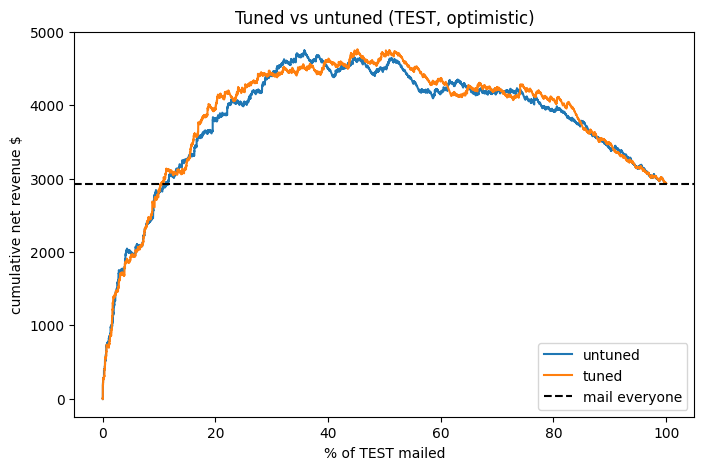


Final recommended production model:
                                                                                                      0
production_strategy                                                                             untuned
response_model                                                                            gbm (untuned)
gift_model                                                                             linreg (untuned)
score                                                     EV = P(TARGET_B) * max(predicted TARGET_D, 0)
TEST_peak_CNR_optimistic                                                                         4750.6
caveat                    Depth and settings chosen on TEST; set the production depth on training data.

Random seeds used in this step:
  step_number                                             action_name seed_value      function_or_parameter notes
          10 tune gbm_target_b {'max_depth': 2, 'n_estimators': 150}         42 clone() 

In [11]:
step_start(10, "HYPERPARAMETER TUNING")
from sklearn.base import clone
from itertools import product

best_ev = ev_summary_df.iloc[0]
best_row = all_approaches_df.iloc[0]
print("Best business strategy so far:", best_row.model, f"TEST peak ${best_row[PEAK]:,.0f}")
b_key, d_key = best_ev.b_model[5:-9], best_ev.d_model[5:-9]          # e.g. "nb", "linreg_log"
print(f"Best expected value model: {best_ev.model}  (response component: {b_key}, gift component: {d_key})")

def resolve_param(est, name):
    """Find the full nested parameter key (e.g. max_depth -> estimator__max_depth inside CalibratedClassifierCV)."""
    keys = est.get_params().keys()
    if name in keys: return name
    hits = sorted([k for k in keys if k.endswith("__" + name)], key=len)
    if not hits: print(f"   WARNING: {name} is not a parameter of {type(est).__name__}; skipped"); return None
    return hits[0]
def tuned_variants(base_model, grid):
    names = list(grid)
    for combo in product(*[grid[n] for n in names]):
        params = {resolve_param(base_model, n): v for n, v in zip(names, combo)}
        params = {k: v for k, v in params.items() if k}
        yield dict(zip(names, combo)), clone(base_model).set_params(**params)
def peak_cnr(score):
    t = cnr_table(score, gift_test); i = int(t.cum_net_revenue.idxmax())
    return float(t.cum_net_revenue[i]), float(t.depth_pct[i]), int(t["rank"][i]), float(t.cum_net_revenue[i] / t.cum_mail_cost[i])

GRIDS_B = {"lr": {"C": [0.01, 0.1, 1.0, 10.0]}, "nb": {"var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3]},
           "gbm": {"max_depth": [2, 3, 4], "n_estimators": [150, 400]}, "nn": {"hidden_layer_sizes": [(8,), (16,), (32,)], "alpha": [1e-4, 1e-2]},
           "rf": {"min_samples_leaf": [20, 50, 100], "max_features": ["sqrt", 0.5]}}
GRIDS_D = {"linreg": {"positive": [False, True]}, "gbm": {"max_depth": [2, 3, 4], "n_estimators": [150, 400]},
           "nn": {"hidden_layer_sizes": [(8,), (16,)], "alpha": [1e-3, 1e-1]}, "rf": {"min_samples_leaf": [5, 10, 25]}}
d_base, d_log = d_key.replace("_log", ""), d_key.endswith("_log")
grid_b, grid_d = GRIDS_B[b_key], GRIDS_D[d_base]
n_combos = int(np.prod([len(v) for v in grid_b.values()]) + np.prod([len(v) for v in grid_d.values()]))
print(f"Tuning {n_combos} combinations (limit 20). Each component is tuned with the other held at its untuned version.")
assert n_combos <= 20

tuning_rows, tuned_preds = [], {}
d_untuned = np.clip(test_full[best_ev.d_model].to_numpy(), 0, None)
p_untuned = test_full[best_ev.b_model].to_numpy()
b_feats = target_b_feature_sets[b_key]
for params, est in tuned_variants(globals()[f"model_{b_key}_target_b"], grid_b):
    log_seed(10, f"tune {b_key}_target_b {params}", RANDOM_STATE, "clone() keeps random_state", "")
    with timed(f"tune {b_key} {params}") as tt: est.fit(train_df[b_feats], y_tr)
    p = est.predict_proba(test_full[b_feats])[:, 1]
    cnr, depth, n_m, roi = peak_cnr(p * d_untuned)
    tuning_rows.append(dict(component=f"{b_key}_target_b", params=json.dumps(params, default=str), test_auc=roc_auc_score(test_full.TARGET_B, p),
                            ev_TEST_peak_cnr=cnr, depth=depth, mailed=n_m, roi=roi, seconds=tt.seconds))
    tuned_preds[("b", json.dumps(params, default=str))] = (est, p)
d_feats = (target_d_log_feature_sets if d_log else target_d_feature_sets)[d_base]
d_target = tr_r.TARGET_D_log1p if d_log else tr_r.TARGET_D
for params, est in tuned_variants(globals()[f"model_{d_key}_target_d"], grid_d):
    log_seed(10, f"tune {d_key}_target_d {params}", RANDOM_STATE, "clone() keeps random_state", "")
    with timed(f"tune {d_key} {params}") as tt: est.fit(tr_r[d_feats], d_target)
    g = est.predict(test_full[d_feats]); g = np.expm1(g) if d_log else g
    cnr, depth, n_m, roi = peak_cnr(p_untuned * np.clip(g, 0, None))
    tuning_rows.append(dict(component=f"{d_key}_target_d", params=json.dumps(params, default=str), test_auc=np.nan,
                            ev_TEST_peak_cnr=cnr, depth=depth, mailed=n_m, roi=roi, seconds=tt.seconds))
    tuned_preds[("d", json.dumps(params, default=str))] = (est, g)
tuning_results_df = pd.DataFrame(tuning_rows)
show(tuning_results_df.round(4), "Tuning results (EV TEST peak, optimistic):"); save_table(tuning_results_df, "tuning_results")

best_b = tuning_results_df[tuning_results_df.component.str.endswith("target_b")].sort_values("ev_TEST_peak_cnr", ascending=False).iloc[0]
best_g = tuning_results_df[tuning_results_df.component.str.endswith("target_d")].sort_values("ev_TEST_peak_cnr", ascending=False).iloc[0]
tuned_b_est, tuned_p = tuned_preds[("b", best_b.params)]
tuned_g_est, tuned_g = tuned_preds[("d", best_g.params)]
globals()[f"tuned_model_{b_key}_target_b"] = tuned_b_est
globals()[f"tuned_model_{d_key}_target_d"] = tuned_g_est
ev_tuned = tuned_p * np.clip(tuned_g, 0, None)
tuned_cnr_table = cnr_table(ev_tuned, gift_test)
cnr, depth, n_m, roi = peak_cnr(ev_tuned)
tuned_vs_untuned_df = pd.DataFrame([
    dict(model=best_ev.model, version="untuned", **{PEAK: best_ev[PEAK]}, depth=best_ev.optimal_depth_pct, mailed=best_ev.mailed_at_optimum, roi=best_ev.roi_at_optimum),
    dict(model=f"{b_key}{best_b.params} x {d_key}{best_g.params}", version="tuned", **{PEAK: cnr}, depth=depth, mailed=n_m, roi=roi)])
show(tuned_vs_untuned_df.round(3), "Tuned vs untuned:"); save_table(tuned_vs_untuned_df, "tuned_vs_untuned")
gain = cnr - best_ev[PEAK]
TUNING_KEEP_THRESHOLD = 0.02          # keep the tuned model only if it gains more than 2% (TEST noise is several hundred dollars)
PRODUCTION_STRATEGY = "tuned" if gain / best_ev[PEAK] > TUNING_KEEP_THRESHOLD else "untuned"
tuning_discussion_df = pd.DataFrame({"topic": ["tuning gain", "risk", "deployment", "decision"], "note": [
    f"${gain:,.0f} change in TEST peak ({gain / best_ev[PEAK]:+.1%}).",
    "Settings were chosen on TEST, so the gain is optimistic; small gains are within TEST-sample noise.",
    "Prefer the simpler untuned model unless the gain holds under cross-validation inside TRAIN.",
    f"Production strategy: {PRODUCTION_STRATEGY} (keep tuned only if the gain exceeds {TUNING_KEEP_THRESHOLD:.0%})."]})
show(tuning_discussion_df, "Tuning discussion:"); save_table(tuning_discussion_df, "discussion")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cnr_tables[best_ev.model].depth_pct * 100, cnr_tables[best_ev.model].cum_net_revenue, label="untuned")
ax.plot(tuned_cnr_table.depth_pct * 100, tuned_cnr_table.cum_net_revenue, label="tuned"); ax.axhline(mail_all, ls="--", c="k", label="mail everyone")
ax.legend(); ax.set_xlabel("% of TEST mailed"); ax.set_ylabel("cumulative net revenue $"); ax.set_title("Tuned vs untuned (TEST, optimistic)")
save_fig(fig, "tuned_vs_untuned")
final_recommendation_df = pd.DataFrame([dict(production_strategy=PRODUCTION_STRATEGY, response_model=f"{b_key}" + (f" {best_b.params}" if PRODUCTION_STRATEGY == "tuned" else " (untuned)"),
    gift_model=f"{d_key}" + (f" {best_g.params}" if PRODUCTION_STRATEGY == "tuned" else " (untuned)"), score="EV = P(TARGET_B) * max(predicted TARGET_D, 0)",
    **{PEAK: cnr if PRODUCTION_STRATEGY == "tuned" else best_ev[PEAK]},
    caveat="Depth and settings chosen on TEST; set the production depth on training data.")])
show(final_recommendation_df.T, "Final recommended production model:"); save_table(final_recommendation_df, "final_recommendation")
tuning_runtime_summary_df = tuning_results_df[["component", "params", "seconds"]]
show_seeds(10)
step_end("tuning_results_df, tuned_model_*, tuned_vs_untuned_df, final_recommendation_df")

## STEP 11 — MEMORY OPTIMIZATION AND OBJECT CLEANUP

In [12]:
step_start(11, "MEMORY OPTIMIZATION AND OBJECT CLEANUP")
import gc
try:
    import psutil; MEMORY_PROFILING_AVAILABLE = True
except ImportError:
    MEMORY_PROFILING_AVAILABLE = False
def rss_mb(): return psutil.Process().memory_info().rss / 1e6 if MEMORY_PROFILING_AVAILABLE else np.nan
def obj_mb(o):
    try:
        if isinstance(o, pd.DataFrame): return o.memory_usage(deep=True).sum() / 1e6
        if isinstance(o, np.ndarray): return o.nbytes / 1e6
        return sys.getsizeof(o) / 1e6
    except Exception: return np.nan

prefix = "tuned_model_" if PRODUCTION_STRATEGY == "tuned" else "model_"
production_components = {"b_model": f"{prefix}{b_key}_target_b", "d_model": f"{prefix}{d_key}_target_d",
                         "b_features": f"target_b_feature_sets['{b_key}']", "d_features": f"{'target_d_log_feature_sets' if d_log else 'target_d_feature_sets'}['{d_base}']",
                         "transforms": "to_transform", "prediction_column": best_ev.model.replace("model_", "pred_")}
print("Preserved production artifacts:"); [print(f"   {k}: {v}") for k, v in production_components.items()]
protected = {"modeling_prepared_df", "train_df", "test_df", "test_full", "tr_r", "te_r", "gift_test", "model_metadata_df", "random_seed_log",
             "notebook_timing_log", "notebook_timing_df", "all_approaches_df", "final_comparison_df", "cnr_summary_df", "ev_summary_df",
             "tuning_results_df", "tuned_vs_untuned_df", "recommendation_summary_df", "final_recommendation_df", "predictions_target_b_train",
             "predictions_target_b_test", "predictions_target_d_train", "predictions_target_d_test", "cnr_tables", "to_transform",
             "target_b_top_features", "model_runtime_summary_df", "tuning_runtime_summary_df", "MEMORY_PROFILING_AVAILABLE", "protected"}
protected |= {k for k, v in list(globals().items()) if k.startswith(("model_", "tuned_model_", "target_")) or k.endswith(("_features", "_feature_sets", "_base"))
              or callable(v) or isinstance(v, types.ModuleType) or k.isupper() or k.startswith("_")}
candidates = ["tuned_preds", "d_untuned", "p_untuned", "ev_tuned", "tuned_p", "tuned_g", "tuned_cnr_table", "imp_sample", "fig", "ax", "axes",
              "est", "p", "g", "ev", "t", "stat", "biz", "sub", "df_raw", "dtypes_df"]
rss_before = rss_mb(); deleted = []
for name in candidates:
    if name in protected or name not in globals(): continue
    deleted.append(dict(object=name, type=type(globals()[name]).__name__, approx_mb=obj_mb(globals()[name])))
    try: del globals()[name]
    except Exception as e: print(f"   WARNING could not delete {name}: {e}")
gc.collect(); rss_after = rss_mb()
deleted_object_summary_df = pd.DataFrame(deleted)
preserved_object_summary_df = pd.DataFrame([{"object": k, "type": type(v).__name__} for k, v in list(globals().items())
                                            if k in protected and not callable(v) and not isinstance(v, types.ModuleType)])
protected_production_artifacts_df = pd.DataFrame(production_components.items(), columns=["role", "object"])
memory_usage_summary_df = pd.DataFrame([dict(rss_before_mb=rss_before, rss_after_mb=rss_after, freed_mb=rss_before - rss_after,
                                             deleted_objects_mb=deleted_object_summary_df.approx_mb.sum() if len(deleted) else 0)])
cleanup_summary_df = pd.DataFrame([dict(deleted=len(deleted), preserved=len(preserved_object_summary_df))])
show(deleted_object_summary_df.round(2), "Deleted objects:"); show(memory_usage_summary_df.round(1), "Memory:")
for nm in ["deleted_object_summary_df", "preserved_object_summary_df", "protected_production_artifacts_df", "memory_usage_summary_df", "cleanup_summary_df"]:
    save_table(globals()[nm], nm.replace("_df", ""))
step_end("cleanup_summary_df, deleted/preserved/protected summaries, memory_usage_summary_df")

RUNNING STEP 11 — MEMORY OPTIMIZATION AND OBJECT CLEANUP
Start: 2026-11-13 22:41:24
Preserved production artifacts:
   b_model: model_gbm_target_b
   d_model: model_linreg_target_d
   b_features: target_b_feature_sets['gbm']
   d_features: target_d_feature_sets['linreg']
   transforms: to_transform
   prediction_column: pred_ev_gbm_x_linreg

Deleted objects:
             object         type  approx_mb
0       tuned_preds         dict       0.00
1         d_untuned      ndarray       0.23
2         p_untuned      ndarray       0.23
3          ev_tuned      ndarray       0.23
4           tuned_p      ndarray       0.23
5           tuned_g      ndarray       0.23
6   tuned_cnr_table    DataFrame       1.60
7        imp_sample    DataFrame       1.75
8               fig       Figure       0.00
9                ax  AxesSubplot       0.00
10             axes      ndarray       0.00
11              est     Pipeline       0.00
12                p      ndarray       0.23
13                g    

## STEP 12 — INPUT SHUFFLING VARIABLE IMPORTANCE

RUNNING STEP 12 — INPUT SHUFFLING VARIABLE IMPORTANCE
Start: 2026-11-13 22:41:24
   [one scoring pass] 0.07 s
Regenerated vs stored production score: max |diff| = 0.00e+00
   [input shuffling (all variables)] 49.33 s

Overall importance (top 10):
              model          feature  rank     ranking_stat  ranking_value  mean_record_variance  median_record_variance  mean_record_std  median_record_std  mean_record_iqr  median_record_iqr  mean_record_mad  median_record_mad  mean_abs_delta  median_abs_delta  p90_abs_delta  fraction_abs_delta_gt_eps  n_rows  n_shuffles   eps  overall_rank
0  production_score    AVGGIFT_log10     1  mean_record_iqr         0.1918                0.0357                  0.0245           0.1705             0.1566           0.1918             0.1745           0.0965             0.0874          0.1977            0.1405         0.4370                     0.9443   28624          20  0.01             1
1  production_score         F_RFA_2A     2  mean_record_iqr    

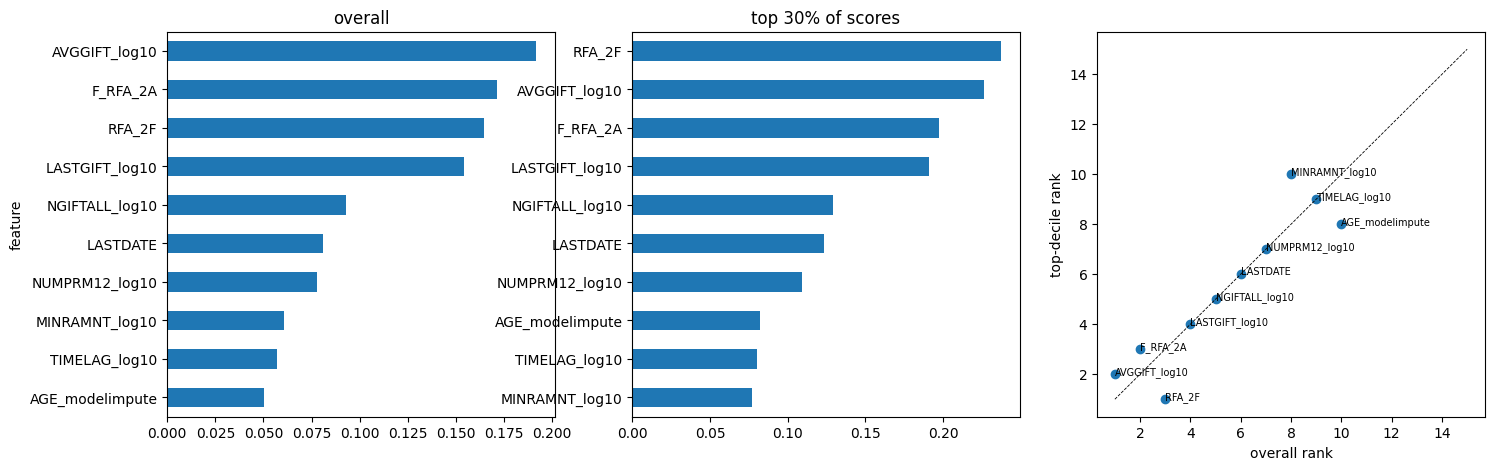


Discussion:
                        topic                                                                                                                                                    note
0            top-decile shift                                                           Variables gaining the most rank in the top 30%: ['RFA_2F', 'AGE_modelimpute', '43_CLUSTER2'].
1  instability vs degradation                                A variable can move many scores a little (high IQR) yet barely change who gets mailed (small CNR drop), and the reverse.
2                   targeting                                                 Variables that matter in the top deciles decide who is mailed; those are the ones to monitor for drift.
3            vs other methods  Input shuffling needs no target and measures score movement per record; permutation importance measures a metric drop; SHAP splits a score additively.
4             per-record view                                                

In [13]:
step_start(12, "INPUT SHUFFLING VARIABLE IMPORTANCE")
N_SHUFFLES = 20
TOP_DECILE_FRACTION = 0.30
MAX_SHUFFLE_SECONDS = 300            # sample TEST rows if the full run would take longer than this

prod_b = globals()[production_components["b_model"]]; prod_d = globals()[production_components["d_model"]]
prod_b_feats = target_b_feature_sets[b_key]
prod_d_feats = (target_d_log_feature_sets if d_log else target_d_feature_sets)[d_base]
shuffle_feature_list = sorted(set(model_features_base))          # ORIGINAL inputs only; derived log1p columns are rebuilt
def production_scorer(X):
    """EV score of the production model from ORIGINAL inputs: P(TARGET_B) * max(predicted TARGET_D, 0)."""
    Xd = X.copy()
    for c in to_transform: Xd[f"{c}_log1p"] = np.log1p(Xd[c])
    p = prod_b.predict_proba(Xd[prod_b_feats])[:, 1]
    g = prod_d.predict(Xd[prod_d_feats]); g = np.expm1(g) if d_log else g
    return p * np.clip(g, 0, None)

X_full = test_full[shuffle_feature_list]
with timed("one scoring pass") as t1: _ = production_scorer(X_full.reset_index(drop=True))
est_s = t1.seconds * len(shuffle_feature_list) * N_SHUFFLES
shuffle_analysis_df = test_full
if est_s > MAX_SHUFFLE_SECONDS:
    n = int(len(test_full) * MAX_SHUFFLE_SECONDS / est_s)
    shuffle_analysis_df = test_full.sample(n, random_state=RANDOM_STATE)
    log_seed(12, "input shuffling sample", RANDOM_STATE, "DataFrame.sample(random_state)", f"{n:,} TEST rows")
    print(f"Full run estimated at {est_s:.0f} s: using a sample of {n:,} TEST rows")
X_base = shuffle_analysis_df[shuffle_feature_list].reset_index(drop=True)
baseline_scores = production_scorer(X_base)
if PRODUCTION_STRATEGY == "untuned":
    stored = test_full.loc[shuffle_analysis_df.index, production_components["prediction_column"]].to_numpy()
    print(f"Regenerated vs stored production score: max |diff| = {np.max(np.abs(baseline_scores - stored)):.2e}")
production_score_test = pd.Series(baseline_scores, index=shuffle_analysis_df.index, name="production_score")
gift_A = shuffle_analysis_df.TARGET_D.to_numpy(float)
base_t = cnr_table(baseline_scores, gift_A); base_depth_n = int(base_t.cum_net_revenue.idxmax()) + 1
def _biz(s):
    t = cnr_table(s, gift_A); return t, int(t.cum_net_revenue.idxmax())
metric_fns = {"max_cum_net_revenue": lambda s: float(_biz(s)[0].cum_net_revenue.max()),
              "roi_at_optimum": lambda s: (lambda t, i: float(t.cum_net_revenue[i] / t.cum_mail_cost[i]))(*_biz(s)),
              "optimal_depth": lambda s: (lambda t, i: float(t.depth_pct[i]))(*_biz(s)),
              "donation_capture_at_base_depth": lambda s: float(cnr_table(s, gift_A).cum_donations[base_depth_n - 1] / gift_A.sum())}
base_metrics = {k: f(baseline_scores) for k, f in metric_fns.items()}
log_seed(12, "input shuffling permutations", RANDOM_STATE, "seeded per feature and shuffle", f"{N_SHUFFLES} shuffles per variable")

try:                                         # Dean's framework
    sys.path.insert(0, str(INPUT_SHUFFLING_SRC))
    from input_shuffling_v2.in_shuff_engine import run_engine
    from input_shuffling_v2.in_shuff_importance import build_feature_summary, record_stat_matrix
    USE_FRAMEWORK = True
except Exception as e:
    print("input_shuffling_v2 not importable, using notebook-native shuffling:", e); USE_FRAMEWORK = False

with timed("input shuffling (all variables)") as tsh:
    if USE_FRAMEWORK:
        cfg = {"run": {"seed": RANDOM_STATE}, "shuffling": {"n_shuffles": N_SHUFFLES}, "importance": {"eps": 0.01, "ranking_stat": "mean_record_iqr"},
               "performance": {"shuffle_batch": 10, "n_jobs": 1}, "schema": {"prediction_columns": ["production_score"]}}
        shuffle_results = run_engine(X_base, [(f, i) for i, f in enumerate(shuffle_feature_list)], production_scorer, baseline_scores, cfg, metric_fns=metric_fns)
        overall_importance_df = build_feature_summary(shuffle_results, cfg)
        record_iqr_df = record_stat_matrix(shuffle_results, "iqr")
        deg = {r.feature: (pd.DataFrame(r.metric_values) if not isinstance(r.metric_values, pd.DataFrame) else r.metric_values) for r in shuffle_results}
    else:
        rng = np.random.default_rng(RANDOM_STATE); iqr_cols, deg, rows = {}, {}, []
        for f in shuffle_feature_list:
            S = np.empty((N_SHUFFLES, len(X_base))); mv = []
            for m in range(N_SHUFFLES):
                Xs = X_base.copy(); Xs[f] = rng.permutation(Xs[f].to_numpy()); S[m] = production_scorer(Xs)
                mv.append({k: fn(S[m]) for k, fn in metric_fns.items()})
            q75, q25 = np.percentile(S, [75, 25], axis=0); iqr_cols[f] = q75 - q25; deg[f] = pd.DataFrame(mv)
            rows.append(dict(feature=f, mean_record_iqr=iqr_cols[f].mean(), median_record_iqr=np.median(iqr_cols[f]),
                             mean_abs_delta=np.abs(S - baseline_scores).mean(), instability_freq=(iqr_cols[f] > 0.01).mean()))
        overall_importance_df = pd.DataFrame(rows); record_iqr_df = pd.DataFrame(iqr_cols)
overall_importance_df = overall_importance_df.sort_values("mean_record_iqr", ascending=False).reset_index(drop=True)
overall_importance_df["overall_rank"] = np.arange(1, len(overall_importance_df) + 1)
top_mask = baseline_scores >= np.quantile(baseline_scores, 1 - TOP_DECILE_FRACTION)
top_decile_importance_df = record_iqr_df[top_mask].mean().rename("mean_record_iqr").to_frame()
top_decile_importance_df["median_record_iqr"] = record_iqr_df[top_mask].median()
top_decile_importance_df = top_decile_importance_df.sort_values("mean_record_iqr", ascending=False)
top_decile_importance_df["top_decile_rank"] = np.arange(1, len(top_decile_importance_df) + 1)
top_decile_importance_df["records_used"] = int(top_mask.sum())
importance_rank_shift_df = overall_importance_df.set_index("feature")[["overall_rank", "mean_record_iqr"]].join(
    top_decile_importance_df[["top_decile_rank", "mean_record_iqr"]], rsuffix="_top")
importance_rank_shift_df["rank_shift"] = importance_rank_shift_df.overall_rank - importance_rank_shift_df.top_decile_rank
importance_rank_shift_df["iqr_change"] = importance_rank_shift_df.mean_record_iqr_top - importance_rank_shift_df.mean_record_iqr
business_degradation_dataframe = pd.DataFrame([{"feature": f, **{f"{k}_degradation": base_metrics[k] - float(np.mean(mv[k])) for k in metric_fns}}
                                               for f, mv in deg.items()]).set_index("feature").join(
    importance_rank_shift_df[["overall_rank", "top_decile_rank", "mean_record_iqr"]])
business_degradation_dataframe["records_used"] = len(X_base)
overall_business_degradation_top10_df = business_degradation_dataframe.sort_values("overall_rank").head(10)
top_decile_business_degradation_top10_df = business_degradation_dataframe.sort_values("top_decile_rank").head(10)
show(overall_importance_df.head(10).round(4), "Overall importance (top 10):")
show(top_decile_importance_df.head(10).round(4), f"Top {TOP_DECILE_FRACTION:.0%} importance (top 10):")
show(overall_business_degradation_top10_df.round(3), "Business degradation, top 10 overall:")
show(top_decile_business_degradation_top10_df.round(3), "Business degradation, top 10 in the top deciles:")
show(importance_rank_shift_df.sort_values("rank_shift", ascending=False).round(4), "Rank shift (positive = more important in the top deciles):")
save_table(overall_importance_df, "overall_importance"); save_table(top_decile_importance_df, "top_decile_importance", index=True)
save_table(importance_rank_shift_df, "rank_shift", index=True); save_table(business_degradation_dataframe, "business_degradation", index=True)
save_table(overall_business_degradation_top10_df, "business_degradation_top10_overall", index=True)
save_table(top_decile_business_degradation_top10_df, "business_degradation_top10_top_deciles", index=True)
movers = importance_rank_shift_df.sort_values("rank_shift", ascending=False).head(3).index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
overall_importance_df.head(10).plot.barh(x="feature", y="mean_record_iqr", ax=ax[0], legend=False); ax[0].invert_yaxis(); ax[0].set_title("overall")
top_decile_importance_df.head(10).mean_record_iqr.plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title(f"top {TOP_DECILE_FRACTION:.0%} of scores")
u = importance_rank_shift_df.loc[sorted(set(overall_importance_df.feature.head(10)) | set(top_decile_importance_df.index[:10]))]
ax[2].scatter(u.overall_rank, u.top_decile_rank)
for f, rr in u.iterrows(): ax[2].annotate(f, (rr.overall_rank, rr.top_decile_rank), fontsize=7)
ax[2].plot([1, len(u) + 5], [1, len(u) + 5], "k--", lw=.6); ax[2].set_xlabel("overall rank"); ax[2].set_ylabel("top-decile rank")
save_fig(fig, "input_shuffling_importance")
input_shuffling_summary_tables = dict(overall=overall_importance_df, top=top_decile_importance_df, shift=importance_rank_shift_df,
                                      degradation=business_degradation_dataframe)
input_shuffling_discussion_df = pd.DataFrame({"topic": ["top-decile shift", "instability vs degradation", "targeting", "vs other methods", "per-record view"], "note": [
    f"Variables gaining the most rank in the top {TOP_DECILE_FRACTION:.0%}: {movers}.",
    "A variable can move many scores a little (high IQR) yet barely change who gets mailed (small CNR drop), and the reverse.",
    "Variables that matter in the top deciles decide who is mailed; those are the ones to monitor for drift.",
    "Input shuffling needs no target and measures score movement per record; permutation importance measures a metric drop; SHAP splits a score additively.",
    "Per-record dispersion shows where the model is fragile, not just an average effect."]})
show(input_shuffling_discussion_df, "Discussion:"); save_table(input_shuffling_discussion_df, "discussion")
show_seeds(12)
step_end("production_scorer, production_score_test, overall/top_decile importance, business_degradation_dataframe",
         notes=f"input shuffling {tsh.seconds:.0f} s ({'framework' if USE_FRAMEWORK else 'notebook-native'})")

## STEP 13 — RESPONSE PROFILES FOR TOP VARIABLES

RUNNING STEP 13 — RESPONSE PROFILES FOR TOP VARIABLES
Start: 2026-11-13 22:42:14
Profile variables (top 3 overall + top 3 in the top deciles, no duplicates): ['AVGGIFT_log10', 'F_RFA_2A', 'RFA_2F']


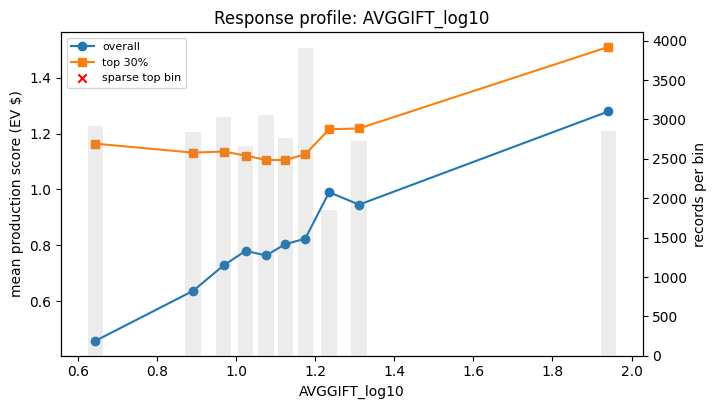


AVGGIFT_log10:
             mid     n  mean_score  n_top  mean_score_top  sparse_overall  sparse_top
bin_order                                                                            
0          0.644  2914       0.458    154           1.164           False       False
1          0.892  2840       0.637    300           1.132           False       False
2          0.969  3034       0.729    509           1.136           False       False
3          1.024  2662       0.780    599           1.121           False       False
4          1.076  3057       0.764    668           1.106           False       False
5          1.124  2766       0.804    778           1.105           False       False
6          1.175  3913       0.824   1270           1.126           False       False
7          1.236  1855       0.990    992           1.215           False       False
8          1.311  2728       0.946   1324           1.218           False       False
9          1.942  2855       1.279   1

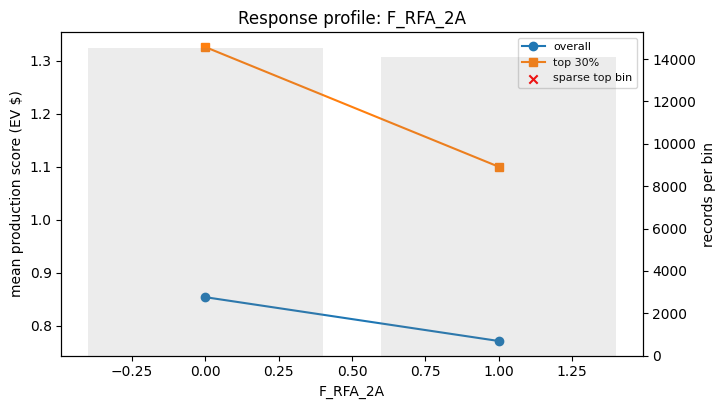


F_RFA_2A:
           mid      n  mean_score  n_top  mean_score_top  sparse_overall  sparse_top
bin_order                                                                           
0          0.0  14536       0.854   5208           1.326           False       False
1          1.0  14088       0.771   3379           1.100           False       False


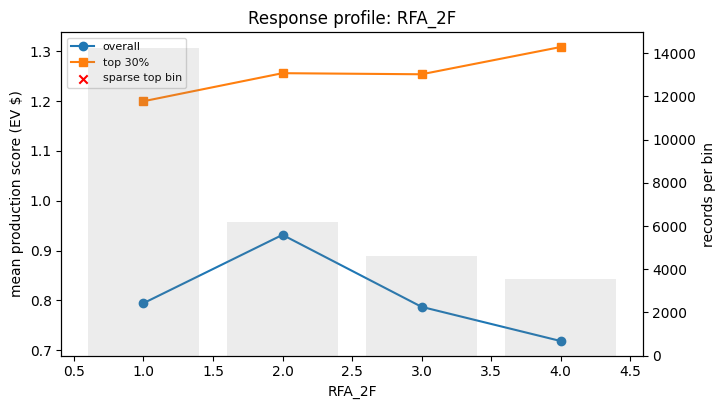


RFA_2F:
           mid      n  mean_score  n_top  mean_score_top  sparse_overall  sparse_top
bin_order                                                                           
0          1.0  14249       0.794   3634           1.200           False       False
1          2.0   6198       0.932   2658           1.256           False       False
2          3.0   4626       0.787   1358           1.254           False       False
3          4.0   3551       0.719    937           1.308           False       False

Sparse bins flagged: 0
STEP 13 COMPLETE — 1.0 s (0.02 min)
Objects created: response_profile_* objects


In [14]:
step_start(13, "RESPONSE PROFILES FOR TOP VARIABLES")
MIN_BIN_RECORDS_OVERALL, MIN_BIN_RECORDS_TOP_DECILE = 50, 30
score = production_score_test
is_top = score >= score.quantile(1 - TOP_DECILE_FRACTION)
top_overall = overall_importance_df.replace(np.inf, np.nan).dropna(subset=["mean_record_iqr"]).feature.head(3).tolist()
top_top = top_decile_importance_df.replace(np.inf, np.nan).dropna(subset=["mean_record_iqr"]).index[:3].tolist()
response_profile_variables = list(dict.fromkeys(top_overall + top_top))
print("Profile variables (top 3 overall + top 3 in the top deciles, no duplicates):", response_profile_variables)
src = modeling_prepared_df.loc[score.index]
response_profile_bin_edges, response_profile_plot_dataframes, sparse_rows, response_profile_plot_objects = {}, {}, [], {}
for v in response_profile_variables:
    x = pd.to_numeric(src[v], errors="coerce")
    if x.nunique() <= 10:                                   # few levels: one bin per level, ordered numerically
        levels = sorted(x.dropna().unique()); response_profile_bin_edges[v] = levels
        tab = pd.DataFrame({"bin_midpoint": x.astype("float64").values, "score": score.values, "top": is_top.values})
        tab["bin_order"] = tab.bin_midpoint.map({l: i for i, l in enumerate(levels)})
    else:                                                    # shared deciles from the overall population
        _, edges = pd.qcut(x, 10, retbins=True, duplicates="drop"); response_profile_bin_edges[v] = edges
        b = pd.cut(x, edges, include_lowest=True)
        tab = pd.DataFrame({"bin": b.values, "score": score.values, "top": is_top.values})
        tab["bin_left"] = tab.bin.apply(lambda i: float(i.left)).astype("float64"); tab["bin_right"] = tab.bin.apply(lambda i: float(i.right)).astype("float64")
        tab["bin_midpoint"] = (tab.bin_left + tab.bin_right) / 2; tab["bin_order"] = pd.Categorical(tab.bin).codes.astype(int)
    tab["score"] = pd.to_numeric(tab.score, errors="coerce")
    g_all = tab.groupby("bin_order").agg(mid=("bin_midpoint", "first"), n=("score", "size"), mean_score=("score", "mean"))
    g_top = tab[tab.top].groupby("bin_order").agg(n_top=("score", "size"), mean_score_top=("score", "mean"))
    prof = g_all.join(g_top, how="left"); prof["n_top"] = prof.n_top.fillna(0).astype(int)
    prof["sparse_overall"] = prof.n < MIN_BIN_RECORDS_OVERALL; prof["sparse_top"] = prof.n_top < MIN_BIN_RECORDS_TOP_DECILE
    response_profile_plot_dataframes[v] = prof; save_table(prof, f"profile_{v}", index=True)
    for o, r in prof[prof.sparse_overall | prof.sparse_top].iterrows():
        sparse_rows.append(dict(variable=v, bin_order=o, midpoint=r.mid, n=r.n, n_top=r.n_top))
    fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax2 = ax.twinx()
    width = (np.diff(prof.mid).min() if len(prof) > 1 else 1) * 0.8
    ax2.bar(prof.mid, prof.n, width=width, alpha=.15, color="gray"); ax2.set_ylabel("records per bin")
    ok = prof[~prof.sparse_overall]; ax.plot(ok.mid, ok.mean_score, "-o", label="overall")
    okt = prof[~prof.sparse_top]; ax.plot(okt.mid, okt.mean_score_top, "s", ls="-" if len(okt) == len(prof) else "none", label=f"top {TOP_DECILE_FRACTION:.0%}")
    sp = prof[prof.sparse_top & (prof.n_top > 0)]; ax.scatter(sp.mid, sp.mean_score_top, marker="x", c="red", label="sparse top bin")
    ax.set_title(f"Response profile: {v}"); ax.set_xlabel(v); ax.set_ylabel("mean production score (EV $)"); ax.legend(fontsize=8)
    response_profile_plot_objects[v] = PLOT_DIR / f"step13_profile_{v}.png"; save_fig(fig, f"profile_{v}")
    show(prof.round(3), f"{v}:")
response_profile_sparse_bins_df = pd.DataFrame(sparse_rows); save_table(response_profile_sparse_bins_df, "sparse_bins")
print(f"\nSparse bins flagged: {len(response_profile_sparse_bins_df)}")
step_end("response_profile_* objects")

## STEP 14 — SUPERVISED ASSOCIATION RULE DISCOVERY (matrix counting; seconds, not an hour)

RUNNING STEP 14 — SUPERVISED ASSOCIATION RULE DISCOVERY
Start: 2026-11-13 22:42:15

Variable pre-selection (32 inputs kept):
           variable                       test  statistic  p_value                                     source
0            RFA_2F                 chi-square   203.1310   0.0000                 chi-square + Step 4 top-10
1         L4D_RFA_2                 chi-square   103.5215   0.0000                 chi-square + Step 4 top-10
2         L1F_RFA_2                 chi-square    37.4003   0.0000                                 chi-square
3    LASTGIFT_log10  ANOVA F (4 quantile bins)    37.2329   0.0000  ANOVA F (4 quantile bins) + Step 4 top-10
4         L1G_RFA_2                 chi-square    34.1422   0.0000                 chi-square + Step 4 top-10
5         L3D_RFA_2                 chi-square    33.9695   0.0000                 chi-square + Step 4 top-10
6    NGIFTALL_log10  ANOVA F (4 quantile bins)    33.2114   0.0000  ANOVA F (4 quantile bins) + Step 4 to

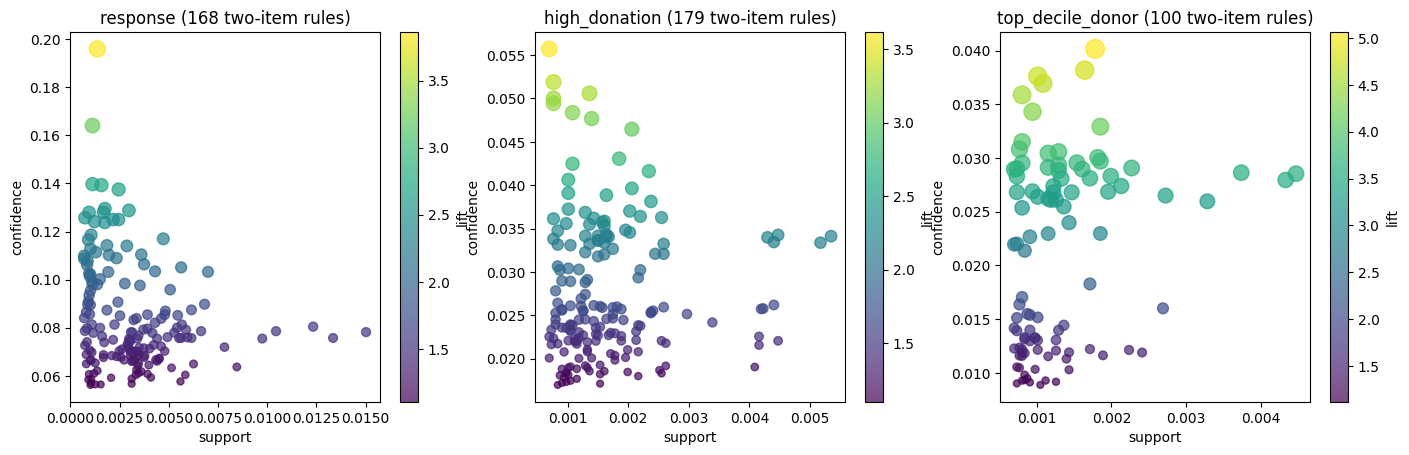

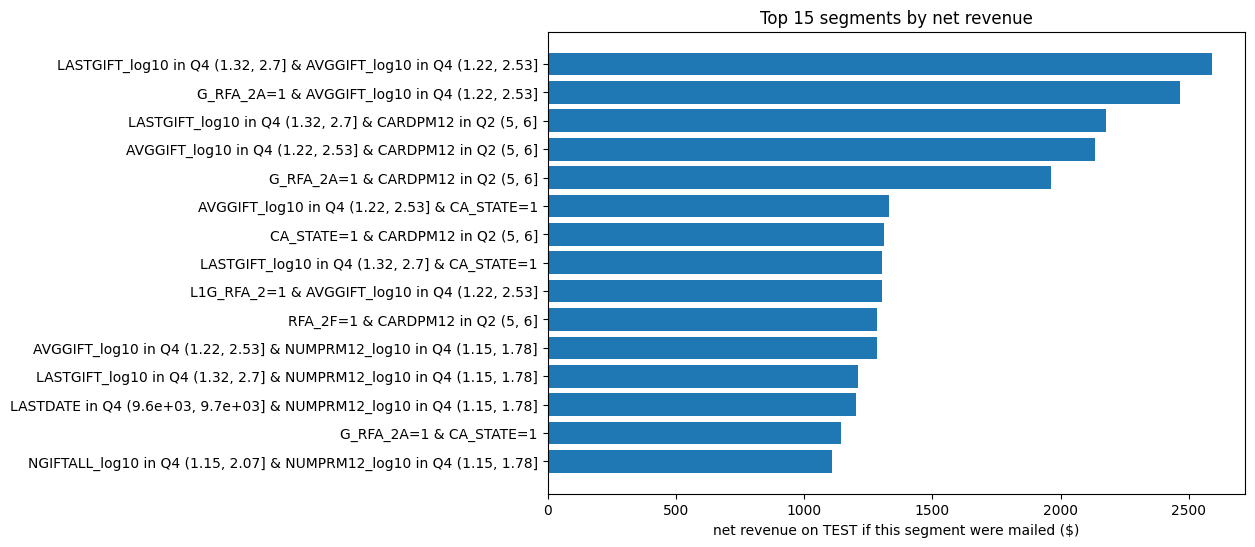


Variables in 2-item rules vs Step 12 input-shuffling ranks and Step 4 top predictors:
                 appearances_in_2item_rules  overall_rank  top_decile_rank  in_step4_top10
LASTDATE                               91.0             6                6            True
NUMPRM12_log10                         84.0             7                7            True
AGE_modelimpute                        81.0            10                8            True
AVGGIFT_log10                          72.0             1                2            True
NGIFTALL_log10                         72.0             5                5            True
TIMELAG_log10                          66.0             9                9            True
MINRAMNT_log10                         62.0             8               10            True
LASTGIFT_log10                         59.0             4                4            True
RFA_2F                                 59.0             3                1            True
CAR

In [15]:
step_start(14, "SUPERVISED ASSOCIATION RULE DISCOVERY")
from scipy import stats
ar_source_df = modeling_prepared_df[modeling_prepared_df["split_flag"] == "TEST"].copy()
MAX_ANTECEDENT_INPUTS, MIN_ANTECEDENT_SUPPORT, MIN_OUTCOME_RECORDS, MIN_LIFT, PARENT_LIFT_GAIN = 50, 0.005, 20, 1.10, 1.05

# Step A: forbidden variables
forbidden = ["PRED", "PROB", "SCORE", "EXPECTED", "EV_", "NET_REVENUE", "CUM_", "DECILE", "LIFT", "ROI", "OUTCOME_", "TARGET", "LOG1P"]
candidates_ar = [c for c in model_features_base if not any(k in c.upper() for k in forbidden)]
# Step B: univariate association with TARGET_B
rank_rows = []
for c in candidates_ar:
    x = ar_source_df[c]
    if x.nunique() <= 10:
        ct = pd.crosstab(x, ar_source_df.TARGET_B); chi2, pv = stats.chi2_contingency(ct)[:2]
        rank_rows.append(dict(variable=c, test="chi-square", statistic=chi2, p_value=pv))
    else:
        bins = pd.qcut(x, 4, duplicates="drop"); groups = [ar_source_df.TARGET_B[bins == b] for b in bins.cat.categories]
        f, pv = stats.f_oneway(*groups); rank_rows.append(dict(variable=c, test="ANOVA F (4 quantile bins)", statistic=f, p_value=pv))
variable_preselection_ranking_df = pd.DataFrame(rank_rows).sort_values("statistic", ascending=False).reset_index(drop=True)
variable_preselection_ranking_df["source"] = variable_preselection_ranking_df.test
# Step C: supplement with Step 4 top predictors
if "target_b_top_features" in globals():
    model_top = sorted({v for vs in target_b_top_features.values() for v in vs})
    variable_preselection_ranking_df.loc[variable_preselection_ranking_df.variable.isin(model_top), "source"] += " + Step 4 top-10"
else:
    print("WARNING: target_b_top_features missing; univariate ranking only"); model_top = []
# Step D: final candidate set
sel = variable_preselection_ranking_df.head(MAX_ANTECEDENT_INPUTS).variable.tolist()
sel += [v for v in model_top if v not in sel and v in candidates_ar]
show(variable_preselection_ranking_df.round(4), f"Variable pre-selection ({len(sel)} inputs kept):")
save_table(variable_preselection_ranking_df, "variable_preselection_ranking")

# transaction matrix: binary -> "=1" item only; few levels -> one item per level; continuous -> 4 quantile bins
items, item_source = {}, {}
for c in sel:
    x = ar_source_df[c]
    if set(x.unique()) <= {0, 1}:
        items[f"ANT::{c}=1"] = (x == 1).to_numpy(); item_source[f"ANT::{c}=1"] = c
    elif x.nunique() <= 10:
        for lv in sorted(x.unique()):
            nm = f"ANT::{c}={lv:g}"; items[nm] = (x == lv).to_numpy(); item_source[nm] = c
    else:
        b = pd.qcut(x, 4, duplicates="drop")
        for i, iv in enumerate(b.cat.categories):
            nm = f"ANT::{c} in Q{i + 1} ({iv.left:.3g}, {iv.right:.3g}]"; items[nm] = (b == iv).to_numpy(); item_source[nm] = c
antecedent_binned_df = pd.DataFrame(items, index=ar_source_df.index)
antecedent_binned_df = antecedent_binned_df.loc[:, antecedent_binned_df.mean().between(MIN_ANTECEDENT_SUPPORT, 0.95)]
pos = ar_source_df.TARGET_D[ar_source_df.TARGET_D > 0]
outcomes = {"CONS::TARGET_B_1": ar_source_df.TARGET_B == 1,
            "CONS::HIGH_DONATION_TOP30": ar_source_df.TARGET_D >= pos.quantile(0.70),
            "CONS::TOP_DECILE_DONOR": ar_source_df.TARGET_D >= pos.quantile(0.90)}
transaction_matrix_supervised = pd.concat([antecedent_binned_df, pd.DataFrame(outcomes)], axis=1).astype(bool)
outcome_rates_df = pd.DataFrame({"outcome": list(outcomes), "records": [int(v.sum()) for v in outcomes.values()],
                                 "rate": [float(v.mean()) for v in outcomes.values()],
                                 "definition": ["TARGET_B == 1", f"TARGET_D >= ${pos.quantile(.7):.2f} (70th pct of gifts)",
                                                f"TARGET_D >= ${pos.quantile(.9):.2f} (90th pct of gifts)"]})
show(outcome_rates_df, f"Outcomes ({antecedent_binned_df.shape[1]} antecedent items, {len(ar_source_df):,} TEST rows):")
save_table(outcome_rates_df, "outcome_rates")

# rule counting with matrix products
ant_cols = list(antecedent_binned_df.columns); src_of = np.array([item_source[c] for c in ant_cols]); N = len(ar_source_df)
with timed("matrix rule counting (all 1- and 2-item rules)") as tcount:
    X = antecedent_binned_df.to_numpy(np.float32)
    n_A, n_AB = X.sum(0), X.T @ X
    iu, ju = np.triu_indices(len(ant_cols), 1)
    keep_pair = (src_of[iu] != src_of[ju]) & (n_AB[iu, ju] / N >= MIN_ANTECEDENT_SUPPORT)
    iu, ju = iu[keep_pair], ju[keep_pair]
    rule_rows = []
    for oc, cvec in outcomes.items():
        c = cvec.to_numpy(np.float32); rate = c.mean(); n_C = c.sum()
        n_AC = X.T @ c; n_ABC = (X * c[:, None]).T @ X
        def _rows(nA, nAC, ants):
            conf = nAC / nA; lift = conf / rate
            a, b_, cc = nAC, nA - nAC, n_C - nAC; d = N - a - b_ - cc                   # 2x2 table antecedent x outcome
            chi2 = N * (a * d - b_ * cc) ** 2 / np.maximum((a + b_) * (cc + d) * (a + cc) * (b_ + d), 1e-9)
            return pd.DataFrame({"antecedents": ants, "consequent": oc, "n_antecedents": [len(x) for x in ants], "support": nAC / N,
                                 "antecedent_support": nA / N, "confidence": conf, "lift": lift, "records_with_outcome": nAC.astype(int), "chi2": chi2})
        singles = _rows(n_A, n_AC, [(ant_cols[i],) for i in range(len(ant_cols))])
        pairs = _rows(n_AB[iu, ju], n_ABC[iu, ju], [(ant_cols[i], ant_cols[j]) for i, j in zip(iu, ju)])
        single_lift = dict(zip(singles.antecedents.str[0], singles.lift))
        pairs["best_parent_lift"] = [max(single_lift[a], single_lift[b]) for a, b in pairs.antecedents]
        rule_rows += [singles, pairs]
    supervised_rules_all = pd.concat(rule_rows, ignore_index=True)
frequent_itemsets_supervised = supervised_rules_all[["antecedents", "antecedent_support"]].drop_duplicates("antecedents")
ok = (supervised_rules_all.records_with_outcome >= MIN_OUTCOME_RECORDS) & (supervised_rules_all.lift >= MIN_LIFT) & \
     (supervised_rules_all.antecedent_support >= MIN_ANTECEDENT_SUPPORT)
beats_parent = (supervised_rules_all.n_antecedents == 1) | (supervised_rules_all.lift >= PARENT_LIFT_GAIN * supervised_rules_all.best_parent_lift)
rules_kept = supervised_rules_all[ok & beats_parent].copy()
rules_kept["antecedent_text"] = rules_kept.antecedents.apply(lambda a: " & ".join(x.replace("ANT::", "") for x in a))
print(f"Rules counted: {len(supervised_rules_all):,}; kept after support / outcome-count / lift / beats-parent filters: {len(rules_kept):,}")
rule_filter_summary_df = supervised_rules_all.assign(kept=ok & beats_parent).groupby(["consequent", "n_antecedents"]).agg(
    counted=("kept", "size"), kept=("kept", "sum")).reset_index()
show(rule_filter_summary_df, "Rules counted and kept:"); save_table(rule_filter_summary_df, "rule_counts")

def rule_mask(ants):
    m = np.ones(N, bool)
    for a in ants: m &= transaction_matrix_supervised[a].to_numpy()
    return m
def profile(rules):
    out = []
    for _, r in rules.iterrows():
        m = rule_mask(r.antecedents); sub = ar_source_df[m]
        n = len(sub); tot = sub.TARGET_D.sum()
        out.append(dict(antecedent_text=r.antecedent_text, consequent=r.consequent, lift=r.lift, confidence=r.confidence, chi2=r.chi2,
                        records_matched=n, response_rate=sub.TARGET_B.mean(), avg_donation=sub.TARGET_D[sub.TARGET_D > 0].mean(),
                        total_donation=tot, mailing_cost=n * MAILING_COST, net_revenue=tot - n * MAILING_COST,
                        net_revenue_per_record=(tot - n * MAILING_COST) / n))
    return pd.DataFrame(out).sort_values("net_revenue", ascending=False).reset_index(drop=True)

rule_sets = {"response": "CONS::TARGET_B_1", "high_donation": "CONS::HIGH_DONATION_TOP30", "top_decile_donor": "CONS::TOP_DECILE_DONOR"}
with timed("rule profiling"):
    for nm, oc in rule_sets.items():
        rs = rules_kept[rules_kept.consequent == oc]
        two = rs[rs.n_antecedents == 2].sort_values(["chi2", "confidence"], ascending=False)
        one = rs[rs.n_antecedents == 1].sort_values(["chi2", "confidence"], ascending=False)
        globals()[f"association_rules_{nm}"] = two
        globals()[f"profile_{nm}_rules"] = profile(two) if len(two) else pd.DataFrame()
        cols = ["antecedent_text", "support", "confidence", "lift", "best_parent_lift", "records_with_outcome", "chi2"]
        show(two[cols].round(4), f"Top 20 two-antecedent rules -> {oc} ({len(two)} kept):", n=20)
        save_table(two[cols], f"rules_{nm}_2ant"); save_table(one[cols[:-2] + ["records_with_outcome", "chi2"]], f"rules_{nm}_1ant")
        if len(two): save_table(globals()[f"profile_{nm}_rules"], f"profile_{nm}_rules")
profile_response_rules, profile_high_donation_rules, profile_top_decile_donor_rules = (
    globals()["profile_response_rules"], globals()["profile_high_donation_rules"], globals()["profile_top_decile_donor_rules"])
for nm in rule_sets:
    pr = globals()[f"profile_{nm}_rules"]
    if len(pr): show(pr.head(10).round(3), f"Profiled {nm} rules (top 10 by net revenue):")

operational_segments_ranked = pd.concat([globals()[f"profile_{nm}_rules"] for nm in rule_sets], ignore_index=True)
if len(operational_segments_ranked):
    operational_segments_ranked = operational_segments_ranked.sort_values("net_revenue", ascending=False).drop_duplicates("antecedent_text").reset_index(drop=True)
    operational_segments_ranked["profitable_segment"] = operational_segments_ranked.net_revenue > 0
show(operational_segments_ranked.head(15).round(3), "Operational segments ranked by net revenue (profitable = net revenue > 0):")
save_table(operational_segments_ranked, "operational_segments_ranked")
avg_nr = (ar_source_df.TARGET_D.sum() - N * MAILING_COST) / N
print(f"For reference, mailing every TEST record nets ${avg_nr:.3f} per record.")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (nm, oc) in zip(axes, rule_sets.items()):
    r = globals()[f"association_rules_{nm}"]
    if len(r): sc = ax.scatter(r.support, r.confidence, s=20 + 40 * (r.lift - 1).clip(0, 5), c=r.lift, cmap="viridis", alpha=.7); fig.colorbar(sc, ax=ax, label="lift")
    ax.set_title(f"{nm} ({len(r)} two-item rules)"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
save_fig(fig, "support_confidence")
if len(operational_segments_ranked):
    top15 = operational_segments_ranked.head(15)
    fig, ax = plt.subplots(figsize=(9, 6)); ax.barh(top15.antecedent_text, top15.net_revenue); ax.invert_yaxis()
    ax.set_xlabel("net revenue on TEST if this segment were mailed ($)"); ax.set_title("Top 15 segments by net revenue"); save_fig(fig, "segment_net_revenue")

# comparison with Steps 4 and 12
rule_vars = pd.Series([item_source[a] for ants in rules_kept[rules_kept.n_antecedents == 2].antecedents for a in ants]).value_counts()
rule_variable_comparison_df = pd.DataFrame({"appearances_in_2item_rules": rule_vars}).join(
    importance_rank_shift_df[["overall_rank", "top_decile_rank"]], how="outer")
rule_variable_comparison_df["in_step4_top10"] = rule_variable_comparison_df.index.isin(model_top)
rule_variable_comparison_df = rule_variable_comparison_df.sort_values("appearances_in_2item_rules", ascending=False)
show(rule_variable_comparison_df.head(20), "Variables in 2-item rules vs Step 12 input-shuffling ranks and Step 4 top predictors:")
save_table(rule_variable_comparison_df, "rules_vs_model_importance", index=True)
ar_discussion_df = pd.DataFrame({"question": ["Do important predictors appear in strong rules?", "Interactions missed by main-effects models?",
    "Interpretability", "Most profitable / responsive segments", "Risk of over-interpreting"], "note": [
    f"Variables most often in rules: {rule_vars.head(5).index.tolist()}; compare with input-shuffling top 5: {overall_importance_df.feature.head(5).tolist()}.",
    "Only pairs whose lift beats both single items by 5% are kept, so the surviving pairs are candidate interactions; confirm them on TRAIN before using them.",
    "A rule is a segment you can describe and mail; a model score is not.",
    f"Top segment: {operational_segments_ranked.antecedent_text.iloc[0] if len(operational_segments_ranked) else 'none'}.",
    "Thousands of rules were tested on the same TEST data already used in Steps 7, 10 and 12: expect some false discoveries. Validate on fresh data."]})
show(ar_discussion_df, "Discussion:"); save_table(ar_discussion_df, "discussion")
step_end("ar_source_df, variable_preselection_ranking_df, transaction_matrix_supervised, supervised_rules_all, association_rules_*, profile_*_rules, operational_segments_ranked",
         notes=f"matrix rule counting {tcount.seconds:.1f} s")

## FINAL NOTEBOOK TIMING REPORT

RUNNING STEP 15 — FINAL NOTEBOOK TIMING REPORT
Start: 2026-11-13 22:42:18

Step runtimes:
    step_number                               step_name  elapsed_seconds  elapsed_minutes               major_runtime_notes
0             1                               LOAD DATA             0.32            0.005                                  
1             2                        DATA PREPARATION             0.26            0.004                                  
2             3                  TRAIN / HOLD-OUT SPLIT             1.73            0.029                                  
3             4    BUILD TARGET_B CLASSIFICATION MODELS            16.00            0.267                                  
4             5        BUILD TARGET_D REGRESSION MODELS             2.01            0.033                                  
5             6       BUILD TRANSFORMED TARGET_D MODELS             2.61            0.043                                  
6             7       CUMULATIVE NET REVEN

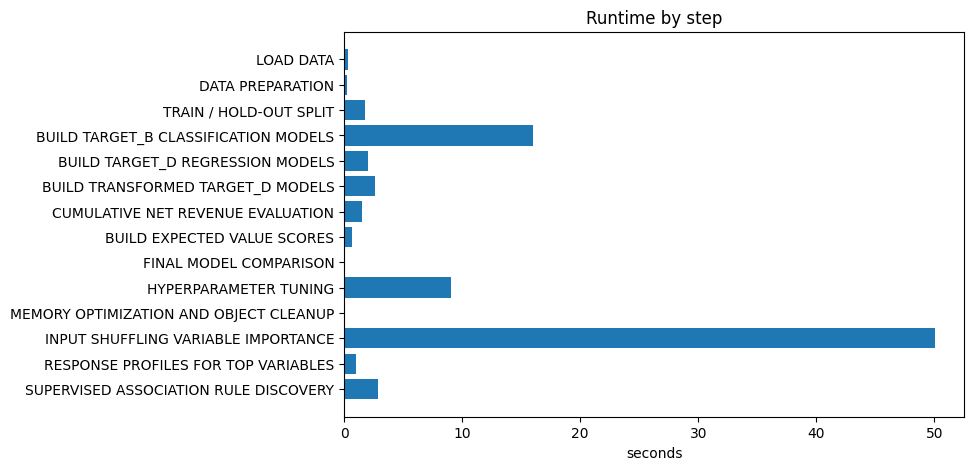


Saved model_metadata, timing, seeds, and TEST predictions for 53 models to reports/
STEP 15 COMPLETE — 0.4 s (0.01 min)
Objects created: notebook_timing_df, model_runtime_summary_df, random_seed_df


In [16]:
step_start(15, "FINAL NOTEBOOK TIMING REPORT")
notebook_timing_df = pd.DataFrame(notebook_timing_log)
show(notebook_timing_df[["step_number", "step_name", "elapsed_seconds", "elapsed_minutes", "major_runtime_notes"]], "Step runtimes:")
print(f"\nTotal notebook runtime: {notebook_timing_df.elapsed_seconds.sum():.0f} s ({notebook_timing_df.elapsed_seconds.sum() / 60:.1f} min)")
show(notebook_timing_df.sort_values("elapsed_seconds", ascending=False).head(3)[["step_name", "elapsed_seconds"]], "Longest steps:")
model_runtime_summary_df = model_metadata_df[["model_name", "approach_type", "train_runtime_seconds", "scoring_runtime_seconds", "total_runtime_seconds"]] \
    .sort_values("total_runtime_seconds", ascending=False)
show(model_runtime_summary_df.head(8).round(2), "Longest-running algorithms:")
random_seed_df = pd.DataFrame(random_seed_log); show(random_seed_df, "Every random action and its seed:")
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(notebook_timing_df.step_name, notebook_timing_df.elapsed_seconds); ax.invert_yaxis()
ax.set_xlabel("seconds"); ax.set_title("Runtime by step"); save_fig(fig, "runtime_by_step")
save_table(notebook_timing_df, "notebook_timing"); save_table(model_runtime_summary_df, "model_runtime_summary")
save_table(tuning_runtime_summary_df, "tuning_runtime_summary"); save_table(random_seed_df, "random_seed_log")
md = model_metadata_df.copy()
for c in ["training_metrics", "testing_metrics"]: md[c] = md[c].apply(lambda d: json.dumps(d, default=float))
save_table(md, "model_metadata")
pred_out = [c for c in modeling_prepared_df.columns if c.startswith("pred_")]
modeling_prepared_df.loc[modeling_prepared_df.split_flag == "TEST", ["RECORD_ID", "TARGET_B", "TARGET_D"] + pred_out].reset_index(drop=True).to_parquet(REPORT_DIR / "test_predictions_all_models.parquet")
print(f"\nSaved model_metadata, timing, seeds, and TEST predictions for {len(pred_out)} models to {REPORT_DIR}/")
step_end("notebook_timing_df, model_runtime_summary_df, random_seed_df")